# PLA FD II DoE Notebook

Rectilinear and concentric measurements, hydrostatic density, regression, ANOVA, interactions, E1 confirmation, and vacuum-response screening for PLA FD II.


In [1]:
# Install once if needed:
# %pip install pandas matplotlib jinja2

import pandas as pd
from IPython.display import display

from pla_doe_measurements import (
    BOX_BEHNKEN_NEW_SCALE_MASS_MEASUREMENTS_G,
    BOX_BEHNKEN_NEW_SCALE_RUN_LABELS,
    EXTRA_RUN_BOX_BEHNKEN_LEVELS,
    EXTRA_RUN_NOZZLE_LINE_WIDTH_LEVELS,
    FD_I_LEVELS,
    FD_II_LEVELS,
    IRONING_FIXED_SETTINGS,
    IRONING_LEVELS,
    IRONING_MASS_MEASUREMENTS_G,
    IRONING_CONFIRMATION_RUNS,
    IRONING_STRINGING_RUNS,
    IRONING_REPEAT_STRINGING_RUNS,
    IRONING_REPEAT_BLOB_COUNTS,
    IRONING_BLOB_COUNTS,
    IRONING_REPEAT_MASS_MEASUREMENTS_G,
    IRONING_RUN_LABELS,
    EXTRA_RUN_MASS_MEASUREMENTS_G,
    EXTRA_RUN_LABELS,
    FD_I_MASS_1_G,
    FD_I_MASS_MEASUREMENTS_G,
    FD_I_HYDROSTATIC_MEASUREMENTS,
    FD_I_REPEAT_MASS_1_G,
    FD_I_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_HYDROSTATIC_MEASUREMENTS,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_RUNS,
    FD_II_CONCENTRIC_RUN_LABELS,
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
)
from DoE_old_scale import (
    FD_I_OLD_SCALE_MASS_MEASUREMENTS_G,
    FD_I_OLD_SCALE_REPEAT_MASS_MEASUREMENTS_G,
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)
from ffd_utils import (
    FACTOR_COLORS,
    build_mass_measurements,
    build_response_measurements,
    build_factor_level_coverage,
    build_repeat_mass_table,
    build_repeat_mass_measurements,
    build_result_matrix,
    build_main_effect_prediction_comparison,
    build_screening_confirmation_comparison,
    plot_mass_quality_tradeoff,
    plot_quality_counts,
    build_mass_quality_tradeoff,
    plot_desirability_ranking,
    build_desirability_table,
    build_ironing_quality_table,
    build_model_anova_table,
    build_term_significance_table,
    build_error_comparison_table,
    build_quadratic_anova_table,
    volume_cm3,
    build_single_mass_table,
    style_extra_run_candidates,
    coded_setting_from_effects,
    build_extra_run_candidates,
    create_box_behnken_design,
    create_two_level_factorial_design,
    calculate_center_point_repeatability,
    calculate_center_curvature,
    calculate_repeatability,
    calculate_pure_error_from_replicates,
    calculate_measurement_error_from_repeated_columns,
    calculate_score_repeatability,
    compute_main_effects,
    fit_quadratic_response_surface,
    format_quadratic_model_formula,
    fit_main_effect_screening_model,
    plot_quadratic_coefficients,
    plot_quadratic_observed_vs_predicted,
    plot_model_anova,
    plot_quadratic_pareto,
    plot_quadratic_response_surface_slices,
    plot_screening_response_contours,
    plot_quadratic_surface_and_contour_pairs,
    create_fractional_factorial_design,
    map_coded_to_real,
    plot_main_effects_bar,
    plot_main_effects_line,
    plot_main_effects_line_comparison,
    plot_screening_model_effects,
    plot_combined_screening_model_effects,
    plot_screening_observed_vs_predicted,
    plot_augmented_model_pareto,
    plot_augmented_main_effects,
    plot_augmented_observed_vs_predicted,
    plot_augmented_residuals,
    plot_screening_half_normal,
    plot_mass_measurements,
    plot_response_measurements,
    plot_combined_mass_measurement_sets,
    plot_center_point_repeatability,
    plot_center_curvature,
    plot_repeatability_summary_comparison,
    plot_three_level_main_effects,
    randomized_second_run_order,
    style_low_high,
    add_interactions,
    compute_interaction_effects,
    plot_interaction_effects,
    plot_interaction_mean_matrix,
)
from notebook_plot_saver import configure_notebook_plot_saving

PLOT_OUTPUT_ROOT = configure_notebook_plot_saving("notebook_figures")
print(f"Notebook figures will be saved under: {PLOT_OUTPUT_ROOT}")

pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)


Notebook figures will be saved under: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


In [2]:
DISPLAY_NAMES = {
    "A_flow_ratio": "Flow Ratio (-)",
    "B_nozzle_temp": "Nozzle Temp (deg C)",
    "C_speed": "Print Speed (mm/s)",
    "D_line_width": "Line Width (mm)",
    "E_layer_height": "Layer Height (mm)",
    "F_walls": "Walls (-)",
}


## 1) DoE Matrix


### FD_II Screening Matrix Without Wall Factors


In [3]:
fd_II_coded_df = create_fractional_factorial_design(include_walls=False)
fd_II_real_df = map_coded_to_real(fd_II_coded_df, FD_II_LEVELS)

display(fd_II_coded_df)
#display(fd_II_real_df)


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height
Run,,,,,
1,-1,-1,-1,-1,1
2,-1,-1,-1,1,1
3,-1,-1,1,-1,1
4,-1,-1,1,1,1
5,-1,1,-1,-1,-1
6,-1,1,-1,1,-1
7,-1,1,1,-1,-1
8,-1,1,1,1,-1
9,1,-1,-1,-1,-1


## 2) Mass Measurements


### FD_II Mass Measurements - RR Rectilinear Pattern


In [4]:
FD_II_RR_RUN_LABELS = [f"RR{run_no}" for run_no in range(1, 17)]
FD_II_RR_MASS_MEASUREMENTS_G = {
    column: values[:16]
    for column, values in FD_II_MASS_MEASUREMENTS_G.items()
}

mass_measurements_g, mass_columns = build_mass_measurements(
    FD_II_RR_MASS_MEASUREMENTS_G,
    run_labels=FD_II_RR_RUN_LABELS,
)

fd_II_e1_inline_mass_values = [
    values[16]
    for values in FD_II_MASS_MEASUREMENTS_G.values()
    if len(values) > 16 and values[16] is not None
]
fd_II_e1_mass_measurement_g = pd.DataFrame({
    "run": ["E1"],
    "mass_mean_g": [pd.Series(fd_II_e1_inline_mass_values, dtype=float).mean()],
}) if fd_II_e1_inline_mass_values else pd.DataFrame(columns=["run", "mass_mean_g"])

display(mass_measurements_g[["run", *mass_columns, "mass_mean_g", "mass_std_g"]])
if not fd_II_e1_mass_measurement_g.empty:
    display(fd_II_e1_mass_measurement_g.round(3))


,run,mass_1_g,mass_mean_g,mass_std_g
0,RR1,84.536,84.5,NaN
1,RR2,84.550,84.6,NaN
2,RR3,84.349,84.3,NaN
3,RR4,84.496,84.5,NaN
4,RR5,85.314,85.3,NaN
5,RR6,84.483,84.5,NaN
6,RR7,85.337,85.3,NaN
7,RR8,84.320,84.3,NaN
8,RR9,88.351,88.4,NaN
9,RR10,87.760,87.8,NaN


,run,mass_mean_g
0,E1,89.077


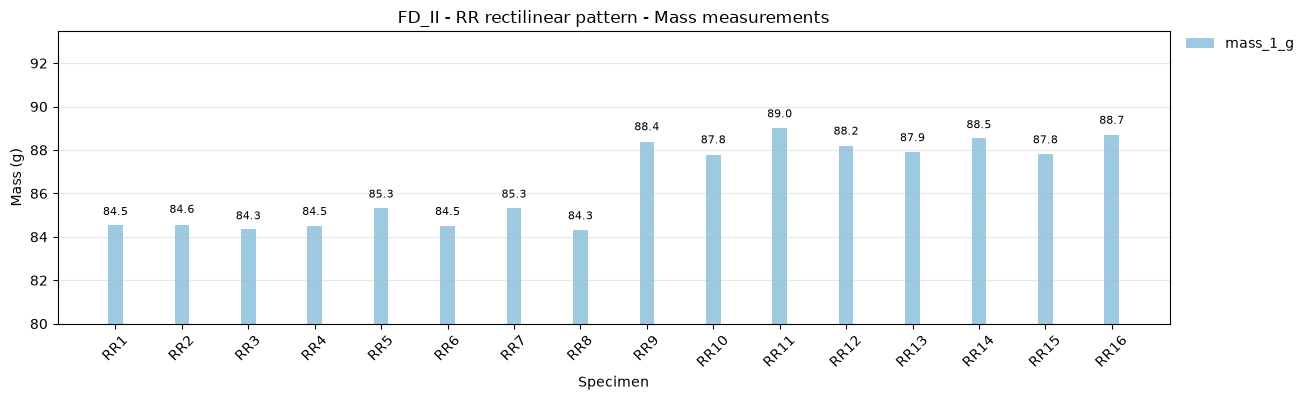

In [5]:
plot_mass_measurements(
    mass_measurements_g,
    mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II - RR rectilinear pattern",
    show_mean_line=False,
)


### FD_II Old-Scale Mass Measurements - RR Rectilinear Pattern

This comparison uses the archived old-scale FD_II measurements. Because four measurements are available, the plotted mean is the cropped mean: the lowest and highest values are discarded and the middle two values are averaged.

,run,mass_1_g,mass_2_g,mass_3_g,mass_4_g,mass_middle_1_g,mass_middle_2_g,mass_mean_g,mass_std_g
0,RR1,82.556,82.670,82.777,82.398,82.556,82.670,82.6,0.080610
1,RR2,83.023,82.844,82.683,82.818,82.818,82.844,82.8,0.018385
2,RR3,82.284,81.861,81.894,81.901,81.894,81.901,81.9,0.004950
3,RR4,82.416,82.028,82.255,81.960,82.028,82.255,82.1,0.160513
4,RR5,83.200,82.788,82.790,82.762,82.788,82.790,82.8,0.001414
5,RR6,83.047,82.046,82.062,82.078,82.062,82.078,82.1,0.011314
6,RR7,83.093,83.138,82.875,82.846,82.875,83.093,83.0,0.154149
7,RR8,82.062,81.796,81.847,82.304,81.847,82.062,82.0,0.152028
8,RR9,86.030,85.997,86.050,85.682,85.997,86.030,86.0,0.023335
9,RR10,85.403,85.419,85.470,85.200,85.403,85.419,85.4,0.011314


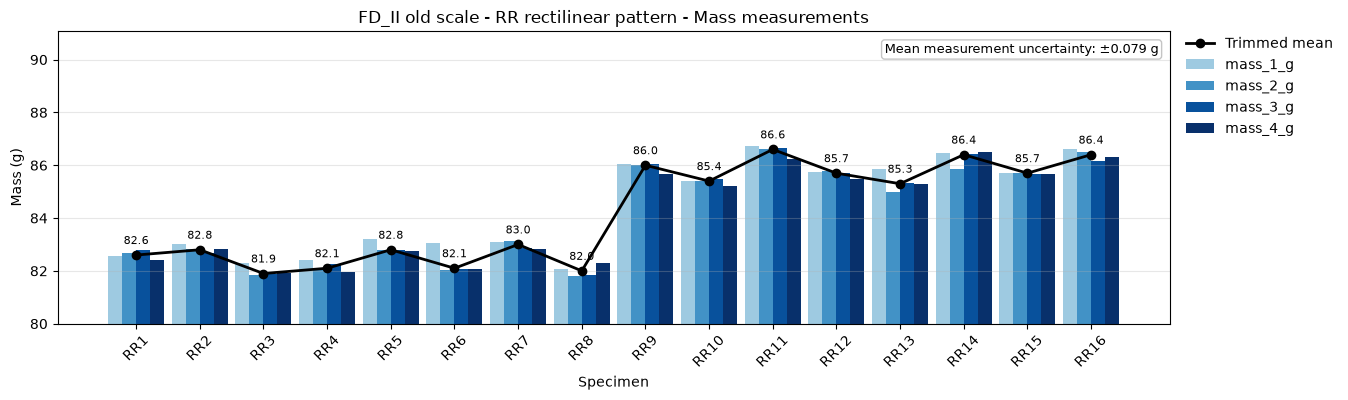

In [6]:
fd_II_old_scale_mass_measurements_g, fd_II_old_scale_mass_columns = build_mass_measurements(
    FD_II_OLD_SCALE_MASS_MEASUREMENTS_G,
)

display(fd_II_old_scale_mass_measurements_g[[
    "run",
    *fd_II_old_scale_mass_columns,
    "mass_middle_1_g",
    "mass_middle_2_g",
    "mass_mean_g",
    "mass_std_g",
]])

plot_mass_measurements(
    fd_II_old_scale_mass_measurements_g,
    fd_II_old_scale_mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II old scale - RR rectilinear pattern",
)


### FD_II Mass Measurements - RR Rectilinear Pattern Sorted by Mass

This is the same FD_II rectilinear mass plot, but the runs are ordered from lowest to highest mean mass.

,run,mass_1_g,mass_mean_g,mass_std_g
0,RR3,84.349,84.300,NaN
1,RR8,84.320,84.300,NaN
2,RR4,84.496,84.500,NaN
3,RR1,84.536,84.500,NaN
4,RR6,84.483,84.500,NaN
5,RR2,84.550,84.600,NaN
6,RR5,85.314,85.300,NaN
7,RR7,85.337,85.300,NaN
8,RR10,87.760,87.800,NaN
9,RR15,87.809,87.800,NaN


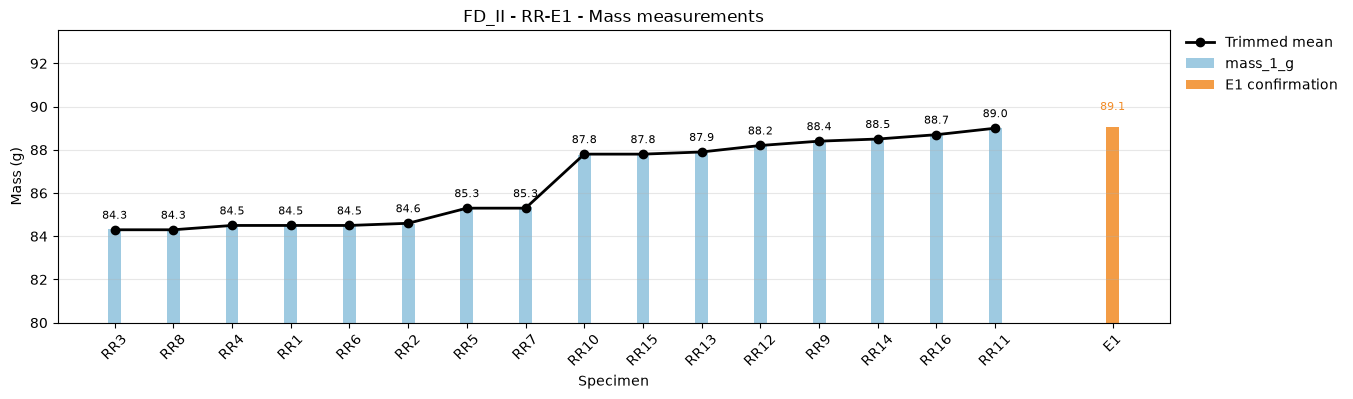

In [7]:
mass_measurements_g_sorted = mass_measurements_g.sort_values(
    "mass_mean_g",
    ascending=True,
)

if not fd_II_e1_mass_measurement_g.empty:
    e1_mass_measurement_g = fd_II_e1_mass_measurement_g.copy()
else:
    e1_index = EXTRA_RUN_LABELS.index("E1")
    e1_measurements_g = [
        values[e1_index]
        for values in EXTRA_RUN_MASS_MEASUREMENTS_G.values()
        if values[e1_index] is not None
    ]
    e1_mass_measurement_g = pd.DataFrame({
        "run": ["E1"],
        "mass_mean_g": [pd.Series(e1_measurements_g, dtype=float).mean()],
    })

sorted_with_e1 = pd.concat(
    [
        mass_measurements_g_sorted[["run", *mass_columns, "mass_mean_g", "mass_std_g"]],
        e1_mass_measurement_g.assign(mass_std_g=pd.NA),
    ],
    ignore_index=True,
)

display(sorted_with_e1)

plot_mass_measurements(
    mass_measurements_g_sorted,
    mass_columns,
    y_min=80,
    mean_label="Trimmed mean",
    experiment="FD_II - RR-E1",
    extra_measurements_g=e1_mass_measurement_g,
    extra_label="E1 confirmation",
    extra_color="#f28e2b",
)


### FD_II Mass Measurements - RC Concentric Pattern


In [8]:
fd_II_concentric_mass_measurements_g, fd_II_concentric_mass_columns = build_mass_measurements(
    FD_II_CONCENTRIC_MASS_MEASUREMENTS_G,
    run_labels=FD_II_CONCENTRIC_RUN_LABELS,
)

display(fd_II_concentric_mass_measurements_g[[
    "run",
    *fd_II_concentric_mass_columns,
    "mass_mean_g",
    "mass_std_g",
]])


,run,mass_1_g,mass_mean_g,mass_std_g
0,RC1,83.862,83.9,NaN
1,RC2,NaN,NaN,NaN
2,RC3,NaN,NaN,NaN
3,RC4,NaN,NaN,NaN
4,RC5,NaN,NaN,NaN
5,RC6,NaN,NaN,NaN
6,RC7,NaN,NaN,NaN
7,RC8,NaN,NaN,NaN
8,RC9,NaN,NaN,NaN
9,RC10,NaN,NaN,NaN


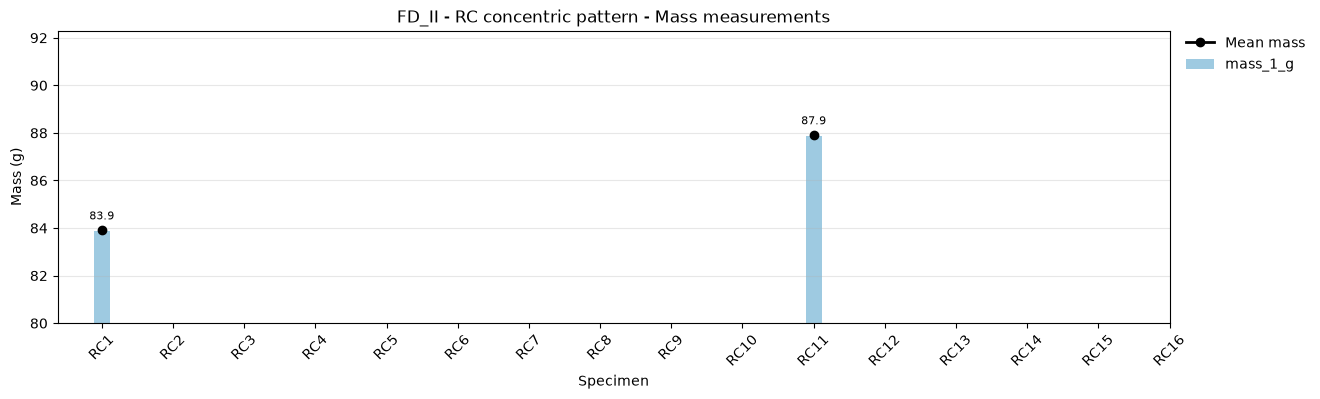

In [9]:
plot_mass_measurements(
    fd_II_concentric_mass_measurements_g,
    fd_II_concentric_mass_columns,
    y_min=80,
    mean_label="Mean mass",
    experiment="FD_II - RC concentric pattern",
)


#### FD_II Repeatability Placeholder


In [10]:
# TODO: Build FD_II repeat measurements and calculate repeatability.
# fd_II_repeatability = calculate_repeatability(
#     mass_measurements_g,
#     fd_II_repeat_mass_measurements_g,
# )
# display(fd_II_repeatability)


## 3) Mass Analysis


### FD_II Screening Analysis


#### FD_II Main-Effect Estimates


In [11]:
mass_result_matrix_II = build_result_matrix(
    fd_II_coded_df,
    mass_measurements_g,
    response="mass_mean_g",
)
#mass_result_matrix_II


In [12]:
main_effect_df = compute_main_effects(mass_result_matrix_II, response="mass_mean_g")
main_effect_df


,Effect,Main effect
0,A_flow_ratio,3.625
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


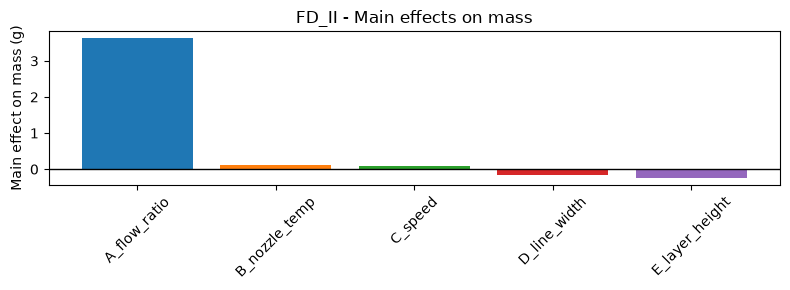

In [13]:
plot_main_effects_bar(
    main_effect_df,
    response="mass_mean_g",
    experiment="FD_II",
)


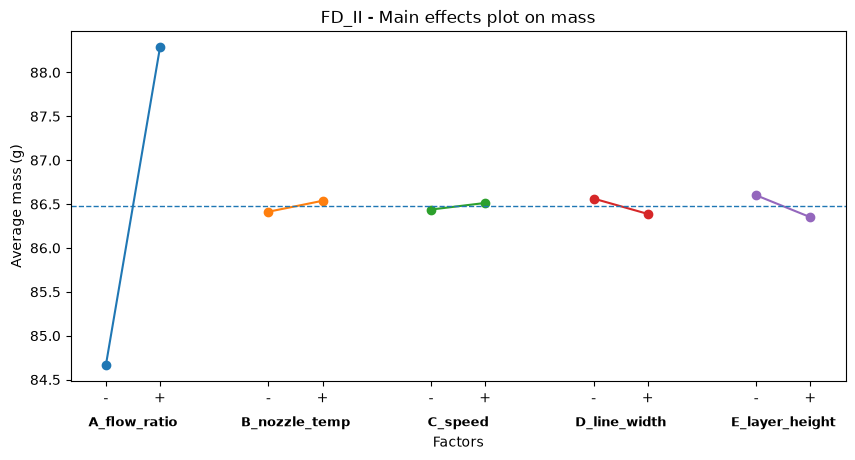

In [14]:
plot_main_effects_line(
    mass_result_matrix_II,
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II RR-Only Regression Main-Effects Plot


This plot uses ordinary regression on the original `RR1` to `RR16` FD_II runs only. 
It does not include E1, so it is the comparable pre-confirmation model.


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,6,6,True,10,0.9624,0.455


,term,coefficient,effect,standard_error,t_value,F_value,p_value
0,Intercept,86.4750,86.475,0.1137,760.2657,578003.9130,0.0000
1,A_flow_ratio,1.8125,3.625,0.1137,15.9350,253.9251,0.0000
2,B_nozzle_temp,0.0625,0.125,0.1137,0.5495,0.3019,0.5947
3,C_speed,0.0375,0.075,0.1137,0.3297,0.1087,0.7484
4,D_line_width,-0.0875,-0.175,0.1137,-0.7693,0.5918,0.4595
5,E_layer_height,-0.1250,-0.250,0.1137,-1.0990,1.2077,0.2975


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,53.02,10.604,51.2271,0.0
1,Residual,10,2.07,0.207,NaN,NaN
2,Total,15,55.09,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,1.8125,0.1137,15.9350,253.9251,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0625,0.1137,0.5495,0.3019,0.5947,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C_speed,0.0375,0.1137,0.3297,0.1087,0.7484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D_line_width,-0.0875,0.1137,-0.7693,0.5918,0.4595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1250,0.1137,-1.0990,1.2077,0.2975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


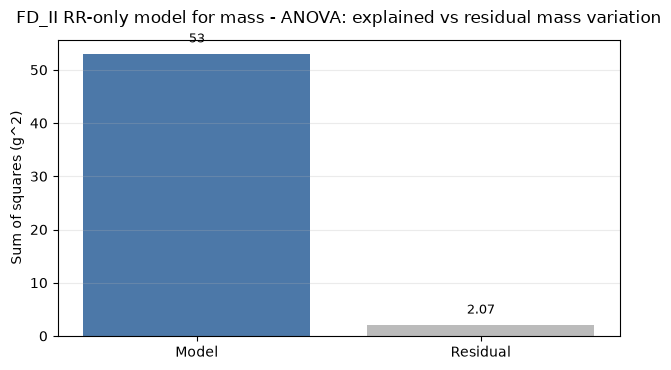

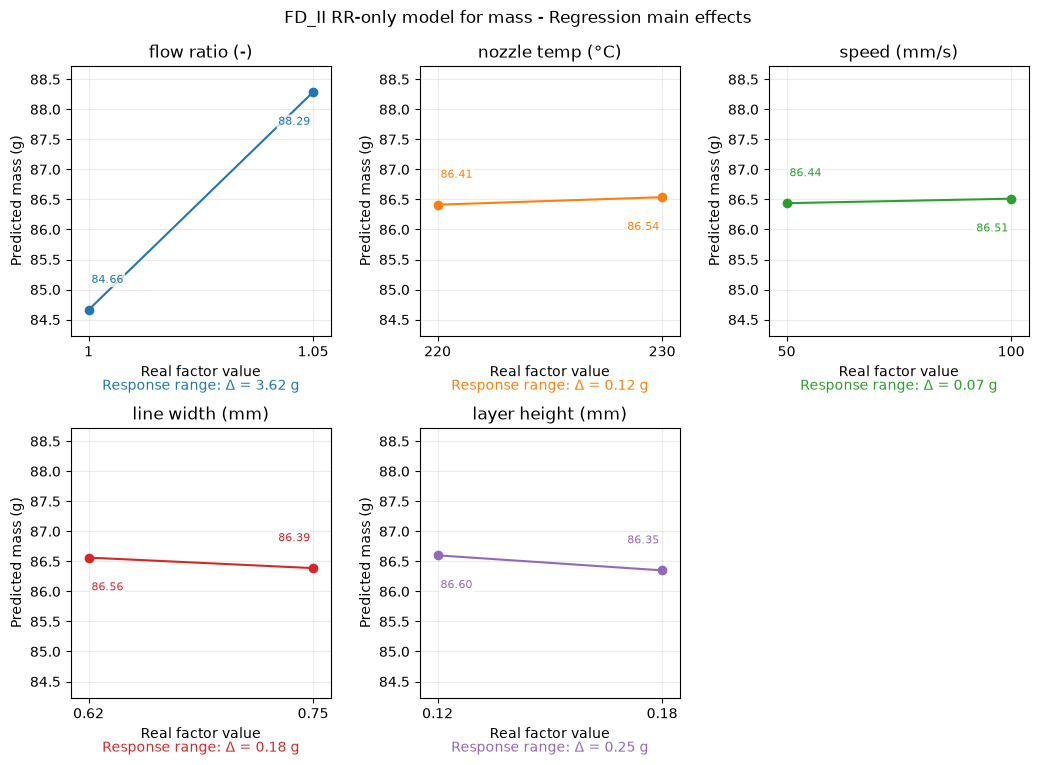

In [15]:
FD_II_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]

fd_II_rr_only_model = fit_main_effect_screening_model(
    mass_result_matrix_II,
    response="mass_mean_g",
    factor_cols=FD_II_FACTOR_COLUMNS,
)

fd_II_rr_only_anova_table = build_model_anova_table(fd_II_rr_only_model)
display(fd_II_rr_only_model["info_df"].round(4))
display(fd_II_rr_only_model["statistics_df"].round(4))
display(fd_II_rr_only_anova_table.round(4))
display(build_term_significance_table(fd_II_rr_only_model).round(4))
plot_model_anova(
    fd_II_rr_only_anova_table,
    response="mass_mean_g",
    experiment="FD_II RR-only model for mass",
)

plot_augmented_main_effects(
    fd_II_rr_only_model,
    FD_II_LEVELS,
    experiment="FD_II RR-only model for mass",
    plot_label="Regression main effects",
)


#### FD_II RR-Only Regression Pareto Plot


This Pareto chart uses the ordinary regression model fitted only to `RR1` to `RR16`. 
It ranks the FD_II main effects by their absolute regression `t` value, so it is directly comparable to the augmented FD_II Pareto plot with E1 added.


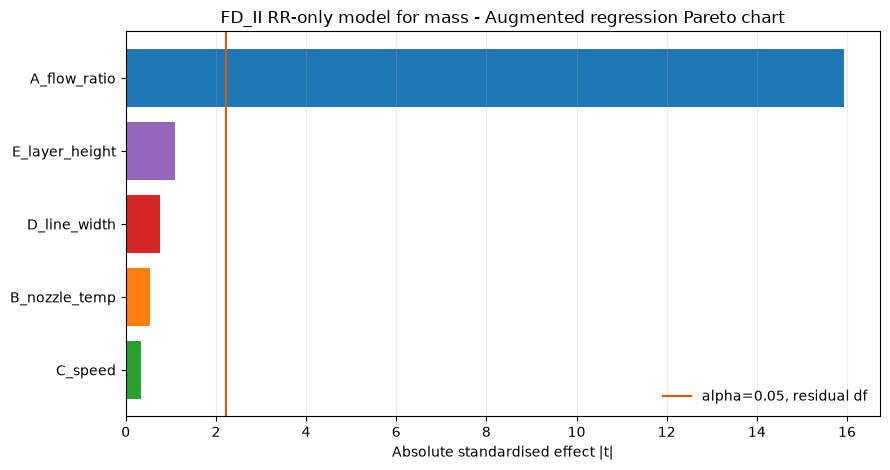

In [16]:
plot_augmented_model_pareto(
    fd_II_rr_only_model,
    experiment="FD_II RR-only model for mass",
)


#### FD_II Main-Effect Estimates Excluding Flow Ratio


In [17]:
main_effect_df_no_flow = main_effect_df[
    main_effect_df["Effect"] != "A_flow_ratio"
].copy()

mass_result_matrix_II_no_flow = mass_result_matrix_II.drop(
    columns=["A_flow_ratio"]
)

main_effect_df_no_flow


,Effect,Main effect
1,B_nozzle_temp,0.125
2,C_speed,0.075
3,D_line_width,-0.175
4,E_layer_height,-0.250


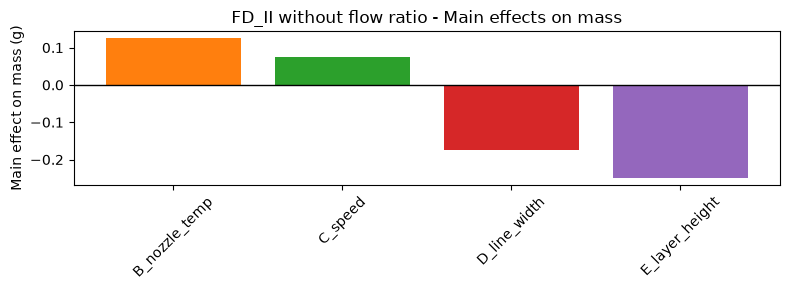

In [18]:
plot_main_effects_bar(
    main_effect_df_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


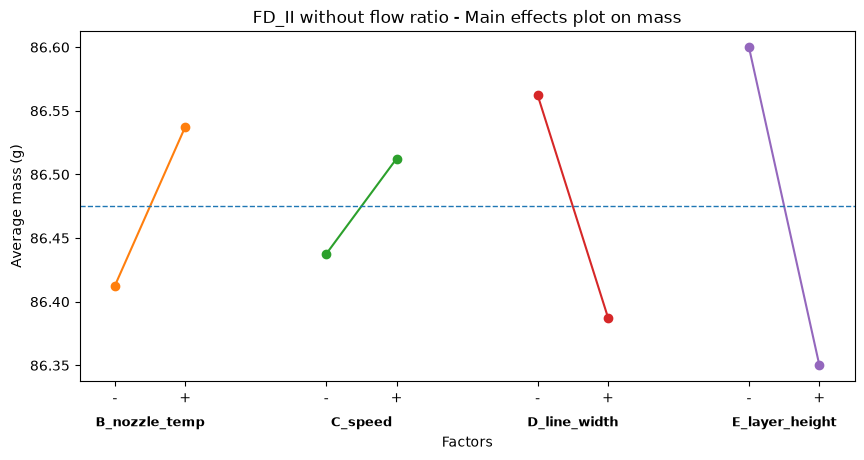

In [19]:
plot_main_effects_line(
    mass_result_matrix_II_no_flow,
    response="mass_mean_g",
    experiment="FD_II without flow ratio",
)


#### FD_II Aliased Interaction Estimates


In [20]:
FD_II_GENERATORS = {
    "E_layer_height": ("A_flow_ratio", "B_nozzle_temp"),  # E = AB
}

interaction_effects_II = compute_interaction_effects(
    mass_result_matrix_II,
    response="mass_mean_g",
    generators=FD_II_GENERATORS,
)

interaction_effects_II


,Interaction,Alias / generator note,Effect
6,B_nozzle_temp x E_layer_height,,3.625000e+00
9,D_line_width x E_layer_height,,6.250000e-01
0,A_flow_ratio x B_nozzle_temp,E_layer_height; generator E=AB,-2.500000e-01
1,A_flow_ratio x C_speed,,2.000000e-01
2,A_flow_ratio x D_line_width,,2.000000e-01
3,A_flow_ratio x E_layer_height,,1.250000e-01
8,C_speed x E_layer_height,,-1.250000e-01
4,B_nozzle_temp x C_speed,,-1.000000e-01
5,B_nozzle_temp x D_line_width,,1.000000e-01
7,C_speed x D_line_width,,1.421085e-14


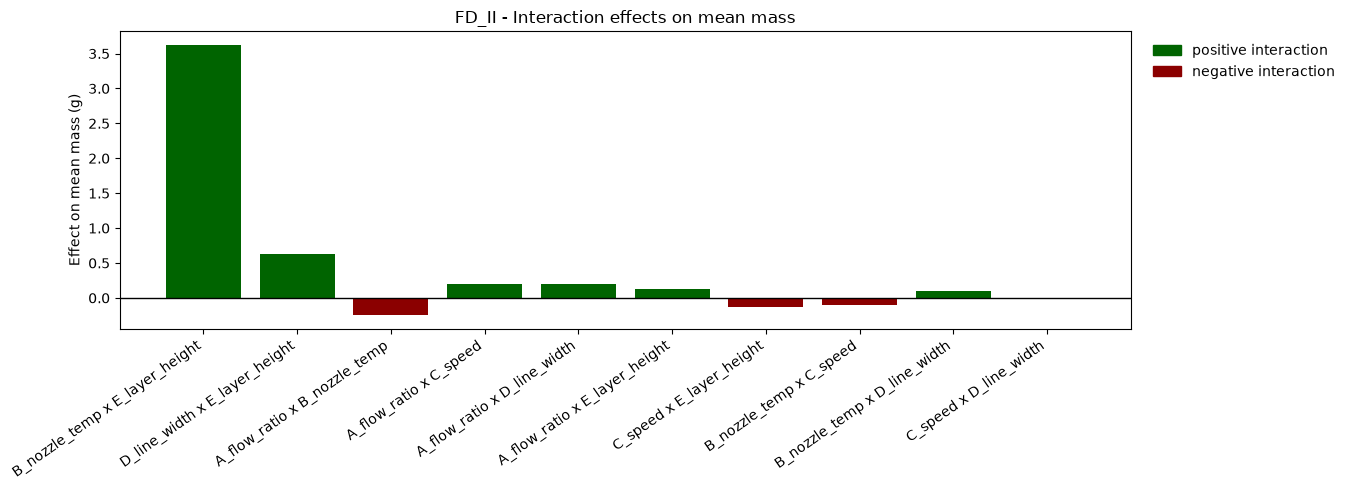

In [21]:
plot_interaction_effects(
    interaction_effects_II,
    experiment="FD_II",
    response="mass_mean_g",
)


#### FD_II Pairwise Interaction Plot Of Data Means


This is the same interaction-matrix view used for FD_I, but applied to the FD_II RR rectilinear mass results. 
Non-parallel or crossing lines suggest possible interaction behavior. 
Because FD_II is also fractional, the visible pairwise patterns should still be interpreted together with the aliasing relation `E = AB`.


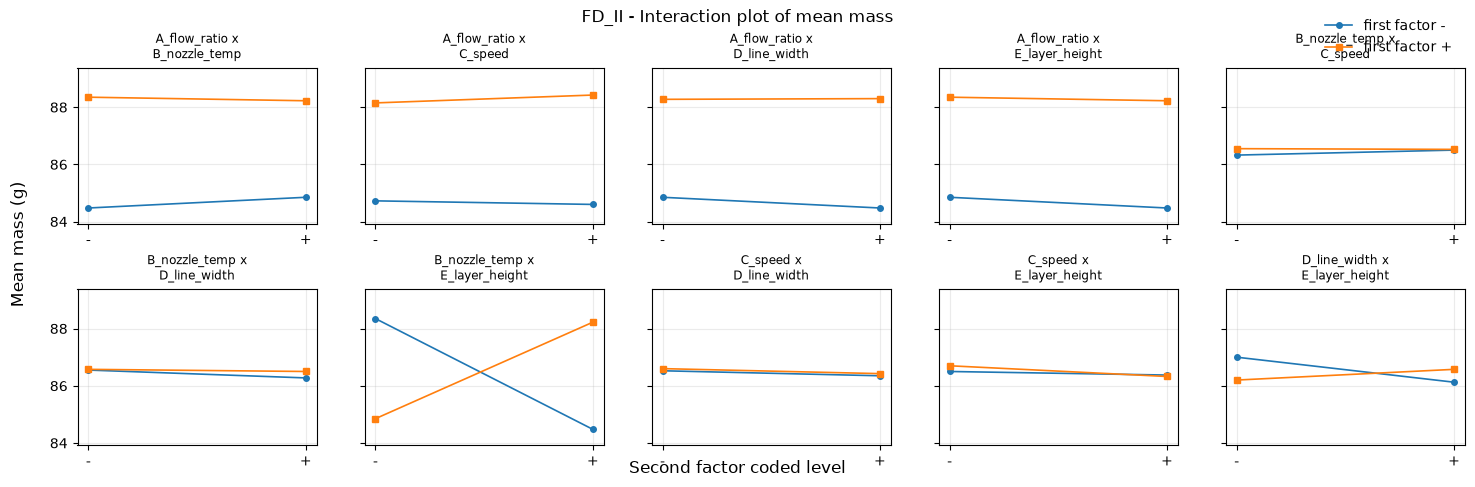

In [22]:
plot_interaction_mean_matrix(
    mass_result_matrix_II,
    response="mass_mean_g",
    experiment="FD_II",
)


#### FD_II Conditional Main Effects: Normal vs Overextrusion Runs


In [23]:
conditional_factor_cols = ["C_speed", "D_line_width"]

mass_result_matrix_II_RR1_8 = mass_result_matrix_II.iloc[:8][
    conditional_factor_cols + ["mass_mean_g"]
].copy()
mass_result_matrix_II_RR9_16 = mass_result_matrix_II.iloc[8:16][
    conditional_factor_cols + ["mass_mean_g"]
].copy()

conditional_effect_df_II_RR1_8 = compute_main_effects(
    mass_result_matrix_II_RR1_8,
    response="mass_mean_g",
)
conditional_effect_df_II_RR9_16 = compute_main_effects(
    mass_result_matrix_II_RR9_16,
    response="mass_mean_g",
)

display(conditional_effect_df_II_RR1_8)
display(conditional_effect_df_II_RR9_16)


,Effect,Main effect
0,C_speed,-0.125
1,D_line_width,-0.375


,Effect,Main effect
0,C_speed,0.275
1,D_line_width,0.025


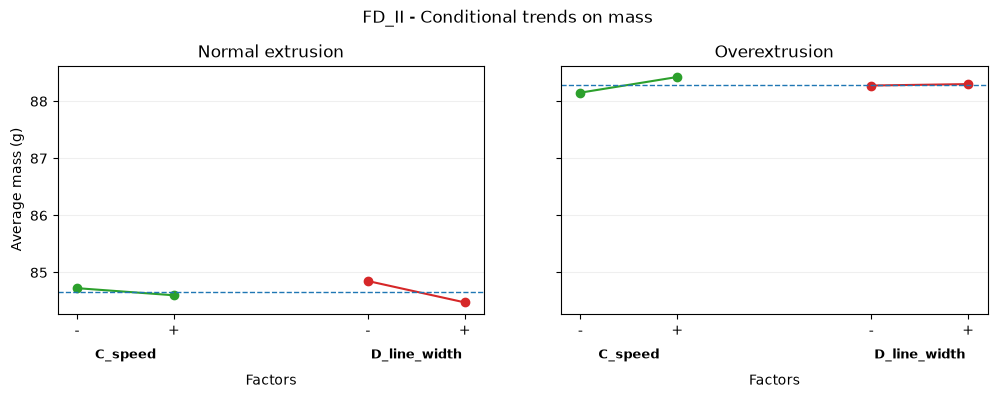

In [24]:
plot_main_effects_line_comparison(
    [mass_result_matrix_II_RR1_8, mass_result_matrix_II_RR9_16],
    labels=["Normal extrusion", "Overextrusion"],
    response="mass_mean_g",
    experiment="FD_II",
)


### E1 Confirmation Run for FD_II


E1 is first treated as an independent confirmation run. The original FD_II model is fitted using only the rectilinear `RR1` to `RR16` runs, then E1 is predicted from its coded settings. 
The confirmation error is `measured E1 - predicted E1`. After this comparison, E1 is added as one extra experimental row in an augmented FD_II model. 
Because the augmented design is no longer perfectly balanced, the augmented effects and Pareto chart use ordinary regression coefficients and regression `t` values, not the original orthogonal factorial effect formulas.


#### Independent E1 Confirmation From RR1-RR16 Only


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,53.02,10.604,51.2271,0.0
1,Residual,10,2.07,0.207,NaN,NaN
2,Total,15,55.09,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,1.8125,0.1137,15.9350,253.9251,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0625,0.1137,0.5495,0.3019,0.5947,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C_speed,0.0375,0.1137,0.3297,0.1087,0.7484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D_line_width,-0.0875,0.1137,-0.7693,0.5918,0.4595,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1250,0.1137,-1.0990,1.2077,0.2975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


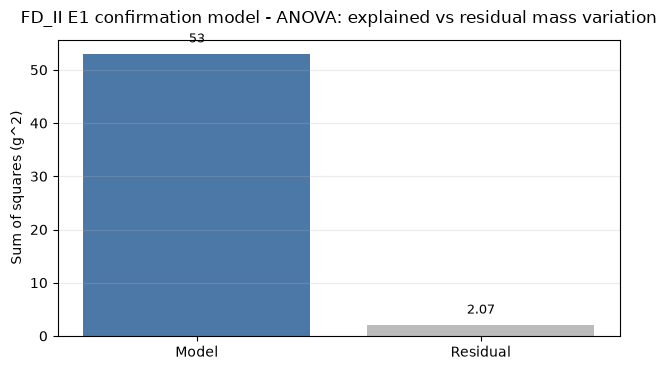

,case,coded_setting,real_setting,predicted_mass_g,measured_mass_g,confirmation_error_g,confirmation_error_percent,fit_data
0,E1 independent confirmation,"{'A_flow_ratio': 1, 'B_nozzle_temp': 1, 'C_spe...","{'A_flow_ratio': 1.05, 'B_nozzle_temp': 230, '...",88.525,89.077,0.552,0.62,RR1-RR16 only


In [25]:
FD_II_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]

# E1 uses the FD_II best-setting confirmation point from the main effects.
# It differs from RR13 only in layer height: E1 has low layer height, RR13 has high layer height.
E1_CODED_SETTING = {
    "A_flow_ratio": 1,
    "B_nozzle_temp": 1,
    "C_speed": -1,
    "D_line_width": -1,
    "E_layer_height": -1,
}

def predict_from_screening_model(model, coded_setting):
    prediction = model["coefficients"]["Intercept"]
    for factor in model["factor_cols"]:
        prediction += model["coefficients"][factor] * coded_setting[factor]
    return prediction

fd_II_e1_inline_mass_values = [
    values[16]
    for values in FD_II_MASS_MEASUREMENTS_G.values()
    if len(values) > 16 and values[16] is not None
]
if fd_II_e1_inline_mass_values:
    e1_raw_mass_values = fd_II_e1_inline_mass_values
else:
    e1_index = EXTRA_RUN_LABELS.index("E1")
    e1_raw_mass_values = [
        values[e1_index]
        for values in EXTRA_RUN_MASS_MEASUREMENTS_G.values()
        if values[e1_index] is not None
    ]
e1_observed_mass_g = pd.Series(e1_raw_mass_values, dtype=float).mean()

# Original confirmation model: fit only RR1-RR16.
fd_II_rr_only_model = fit_main_effect_screening_model(
    mass_result_matrix_II,
    response="mass_mean_g",
    factor_cols=FD_II_FACTOR_COLUMNS,
)
fd_II_e1_confirmation_anova_table = build_model_anova_table(fd_II_rr_only_model)
display(fd_II_e1_confirmation_anova_table.round(4))
display(build_term_significance_table(fd_II_rr_only_model).round(4))
plot_model_anova(
    fd_II_e1_confirmation_anova_table,
    response="mass_mean_g",
    experiment="FD_II E1 confirmation model",
)

e1_predicted_from_rr_only = predict_from_screening_model(
    fd_II_rr_only_model,
    E1_CODED_SETTING,
)

fd_II_e1_confirmation = pd.DataFrame([
    {
        "case": "E1 independent confirmation",
        "coded_setting": E1_CODED_SETTING,
        "real_setting": {
            factor: FD_II_LEVELS[factor][coded]
            for factor, coded in E1_CODED_SETTING.items()
        },
        "predicted_mass_g": e1_predicted_from_rr_only,
        "measured_mass_g": e1_observed_mass_g,
        "confirmation_error_g": e1_observed_mass_g - e1_predicted_from_rr_only,
        "confirmation_error_percent": 100 * (e1_observed_mass_g - e1_predicted_from_rr_only) / e1_observed_mass_g,
        "fit_data": "RR1-RR16 only",
    }
])

display(fd_II_e1_confirmation.round({
    "predicted_mass_g": 3,
    "measured_mass_g": 3,
    "confirmation_error_g": 3,
    "confirmation_error_percent": 2,
}))


#### Augmented FD_II Model With E1 Added


In [26]:
fd_II_rr_labeled_result_matrix = mass_result_matrix_II.copy()
fd_II_rr_labeled_result_matrix["Run"] = [
    f"RR{run_no}" for run_no in range(1, len(fd_II_rr_labeled_result_matrix) + 1)
]

e1_augmented_row = pd.DataFrame([{
    "Run": "E1",
    **E1_CODED_SETTING,
    "mass_mean_g": e1_observed_mass_g,
}])
fd_II_augmented_result_matrix = pd.concat(
    [fd_II_rr_labeled_result_matrix, e1_augmented_row],
    ignore_index=True,
)

display(fd_II_augmented_result_matrix.tail())

# Augmented fractional factorial model: ordinary regression on RR1-RR16 + E1.
fd_II_augmented_model = fit_main_effect_screening_model(
    fd_II_augmented_result_matrix,
    response="mass_mean_g",
    factor_cols=FD_II_FACTOR_COLUMNS,
)

display(fd_II_augmented_model["info_df"].round(4))

fd_II_augmented_anova_table = build_model_anova_table(fd_II_augmented_model)
display(fd_II_augmented_anova_table.round(4))
display(build_term_significance_table(fd_II_augmented_model).round(4))

fd_II_augmented_effects = (
    fd_II_augmented_model["statistics_df"]
    .query("term != 'Intercept'")
    .copy()
)
fd_II_augmented_effects = fd_II_augmented_effects.rename(
    columns={"effect": "effect_low_to_high"}
)
fd_II_augmented_effects["absolute_t"] = fd_II_augmented_effects["t_value"].abs()
fd_II_augmented_effects = fd_II_augmented_effects.sort_values(
    "absolute_t",
    ascending=False,
)

display(fd_II_augmented_effects.round({
    "coefficient": 4,
    "effect_low_to_high": 4,
    "standard_error": 4,
    "t_value": 3,
    "p_value": 4,
    "absolute_t": 3,
}))


,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height,mass_mean_g,Run
12,1,1,-1,-1,1,87.900,RR13
13,1,1,-1,1,1,88.500,RR14
14,1,1,1,-1,1,87.800,RR15
15,1,1,1,1,1,88.700,RR16
16,1,1,-1,-1,-1,89.077,E1


,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,17,6,6,True,11,0.9627,0.4564


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,59.1705,11.8341,56.8053,0.0
1,Residual,11,2.2916,0.2083,NaN,NaN
2,Total,16,61.4621,NaN,NaN,NaN


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,1.8376,0.1115,16.4830,271.6904,0.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,B_nozzle_temp,0.0876,0.1115,0.7857,0.6173,0.4486,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C_speed,0.0124,0.1115,0.1113,0.0124,0.9134,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,D_line_width,-0.1126,0.1115,-1.0099,1.0200,0.3342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,E_layer_height,-0.1501,0.1115,-1.3463,1.8125,0.2053,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,term,coefficient,effect_low_to_high,standard_error,t_value,F_value,p_value,absolute_t
1,A_flow_ratio,1.8376,3.6752,0.1115,16.483,271.690439,0.0000,16.483
5,E_layer_height,-0.1501,-0.3002,0.1115,-1.346,1.812531,0.2053,1.346
4,D_line_width,-0.1126,-0.2252,0.1115,-1.010,1.019960,0.3342,1.010
2,B_nozzle_temp,0.0876,0.1752,0.1115,0.786,0.617298,0.4486,0.786
3,C_speed,0.0124,0.0248,0.1115,0.111,0.012390,0.9134,0.111


#### Augmented FD_II Regression Plots


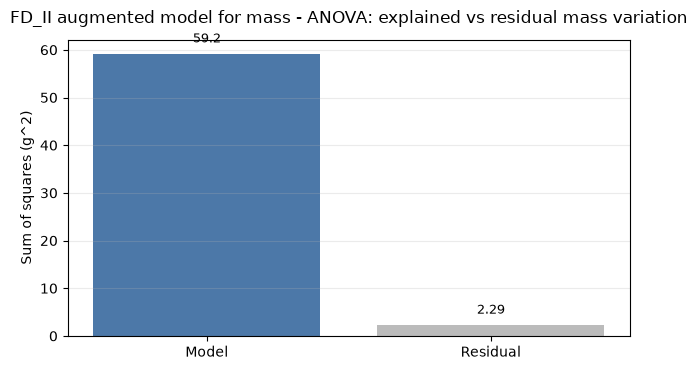

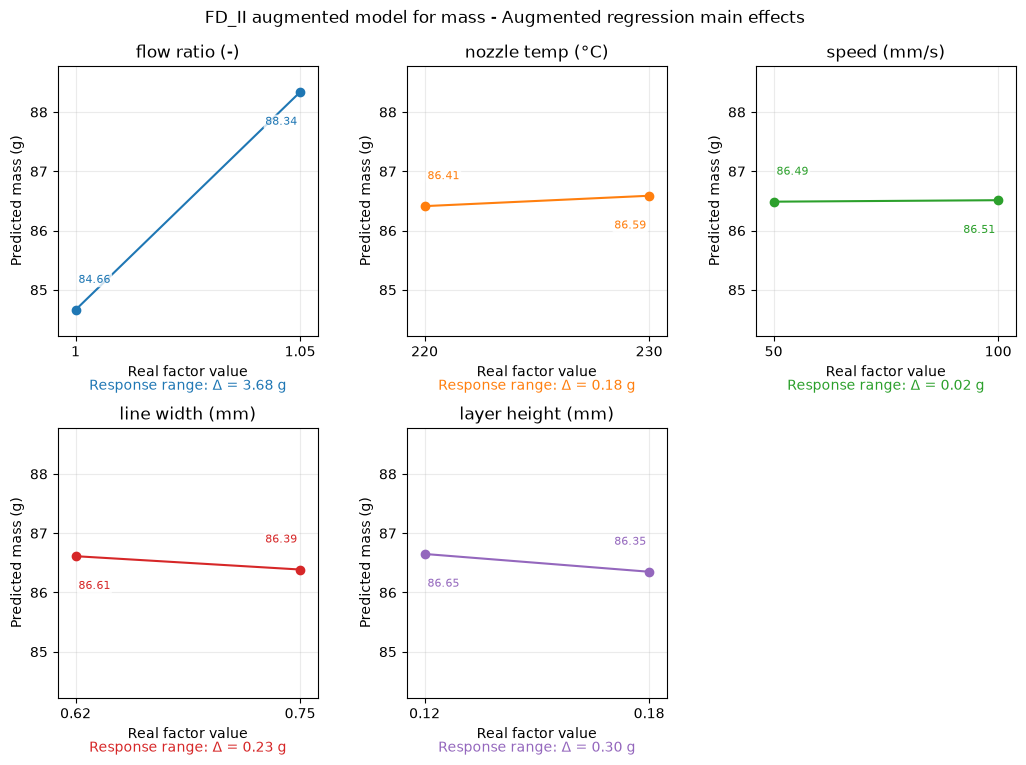

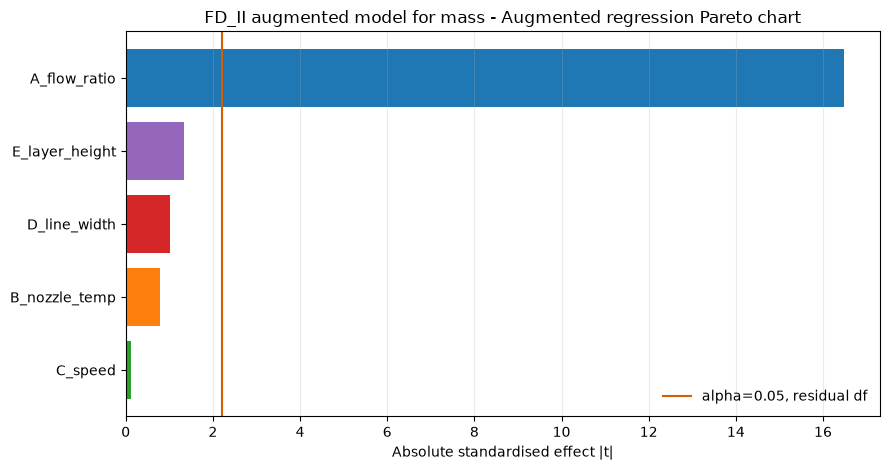

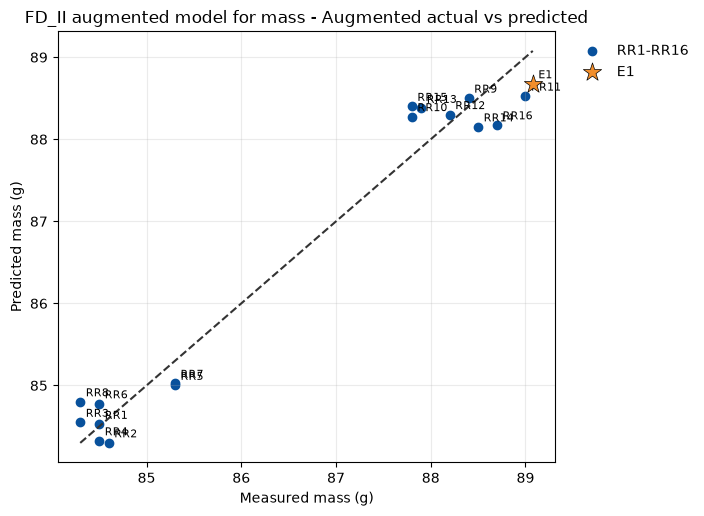

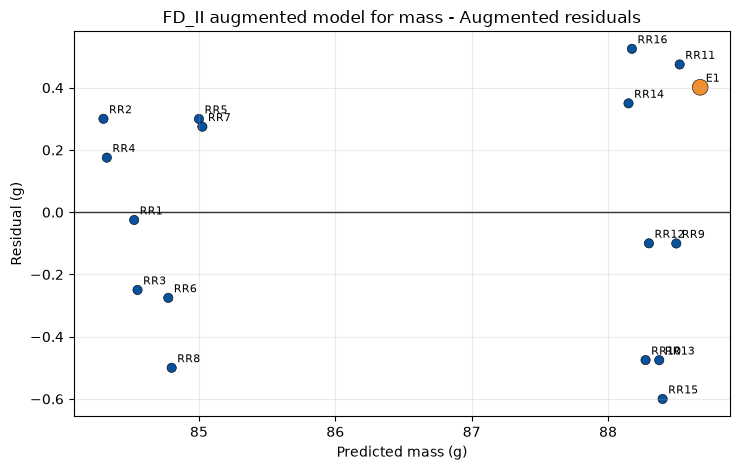

In [27]:
plot_model_anova(
    fd_II_augmented_anova_table,
    response="mass_mean_g",
    experiment="FD_II augmented model for mass",
)

plot_augmented_main_effects(
    fd_II_augmented_model,
    FD_II_LEVELS,
    experiment="FD_II augmented model for mass",
)
plot_augmented_model_pareto(
    fd_II_augmented_model,
    experiment="FD_II augmented model for mass",
)
plot_augmented_observed_vs_predicted(
    fd_II_augmented_model,
    confirmation_run="E1",
    experiment="FD_II augmented model for mass",
)
plot_augmented_residuals(
    fd_II_augmented_model,
    confirmation_run="E1",
    experiment="FD_II augmented model for mass",
)


#### E1 Compared With RR13


In [28]:
fd_II_e1_vs_rr13 = fd_II_augmented_result_matrix.loc[
    fd_II_augmented_result_matrix["Run"].isin(["RR13", "E1"]),
    ["Run", *FD_II_FACTOR_COLUMNS, "mass_mean_g"],
].copy()
for factor in FD_II_FACTOR_COLUMNS:
    fd_II_e1_vs_rr13[f"{factor}_real"] = fd_II_e1_vs_rr13[factor].map(FD_II_LEVELS[factor])

display(fd_II_e1_vs_rr13[[
    "Run",
    *[f"{factor}_real" for factor in FD_II_FACTOR_COLUMNS],
    "mass_mean_g",
]].round(3))


,Run,A_flow_ratio_real,B_nozzle_temp_real,C_speed_real,D_line_width_real,E_layer_height_real,mass_mean_g
12,RR13,1.05,230,50,0.62,0.18,87.900
16,E1,1.05,230,50,0.62,0.12,89.077


## 4) Density Analysis


### Hydrostatic Measurements

## Hydrostatic Measurements - RR Rectilinear Pattern

Hydrostatic measurements use the first two repeats for `RR1`-`RR15` and `E1`. Unfinished `RR16` remains excluded, and spreadsheet `0.00` placeholders are not treated as measurements. The repeated air/water measurements belong to the same printed specimen and therefore estimate measurement uncertainty rather than print-to-print repeatability.


In [29]:
fd_II_hydrostatic_tables = {}
fd_II_hydrostatic_columns = {}

for response_name, measurements in FD_II_HYDROSTATIC_MEASUREMENTS.items():
    fd_II_run_labels = [*[f"RR{i}" for i in range(1, 17)], "E1"]
    mean_digits = 2 if response_name == "relative_density_percent" else 3
    table, columns = build_response_measurements(
        measurements,
        run_labels=fd_II_run_labels,
        response_name=response_name,
        mean_round_digits=mean_digits,
    )
    fd_II_hydrostatic_tables[response_name] = table
    fd_II_hydrostatic_columns[response_name] = columns

fd_II_hydrostatic_summary = fd_II_hydrostatic_tables["weight_in_air_g"][["run"]].copy()
for response_name, table in fd_II_hydrostatic_tables.items():
    fd_II_hydrostatic_summary[f"{response_name}_mean"] = table[f"{response_name}_mean"]
    fd_II_hydrostatic_summary[f"{response_name}_std"] = table[f"{response_name}_std"]

fd_II_hydrostatic_summary = fd_II_hydrostatic_summary.dropna(
    subset=["density_g_cm3_mean"]
)
display(fd_II_hydrostatic_summary.round({
    "weight_in_air_g_mean": 3,
    "weight_in_air_g_std": 3,
    "weight_in_water_g_mean": 3,
    "weight_in_water_g_std": 3,
    "volume_cm3_mean": 3,
    "volume_cm3_std": 3,
    "density_g_cm3_mean": 3,
    "density_g_cm3_std": 3,
    "relative_density_percent_mean": 2,
    "relative_density_percent_std": 2,
}))


,run,weight_in_air_g_mean,weight_in_air_g_std,weight_in_water_g_mean,weight_in_water_g_std,volume_cm3_mean,volume_cm3_std,density_g_cm3_mean,density_g_cm3_std,relative_density_percent_mean,relative_density_percent_std
0,RR1,82.550,0.042,63.145,0.120,63.255,0.120,1.305,0.007,97.78,0.23
1,RR2,82.555,0.049,63.110,0.099,63.220,0.099,1.305,0.007,97.84,0.21
2,RR3,82.315,0.064,63.185,0.007,63.295,0.007,1.300,0.000,97.44,0.08
3,RR4,82.580,0.057,62.995,0.134,63.105,0.134,1.310,0.000,98.05,0.14
4,RR5,83.295,0.021,63.920,0.127,64.040,0.127,1.300,0.000,97.47,0.17
5,RR6,82.445,0.120,63.215,0.078,63.325,0.078,1.300,0.000,97.55,0.27
6,RR7,83.350,0.028,63.950,0.014,64.070,0.014,1.300,0.000,97.49,0.01
7,RR8,82.295,0.035,63.110,0.014,63.220,0.014,1.300,0.000,97.54,0.02
8,RR9,86.300,0.000,64.955,0.346,65.075,0.346,1.325,0.007,99.38,0.53
9,RR10,85.680,0.000,64.600,0.212,64.720,0.212,1.325,0.007,99.20,0.33


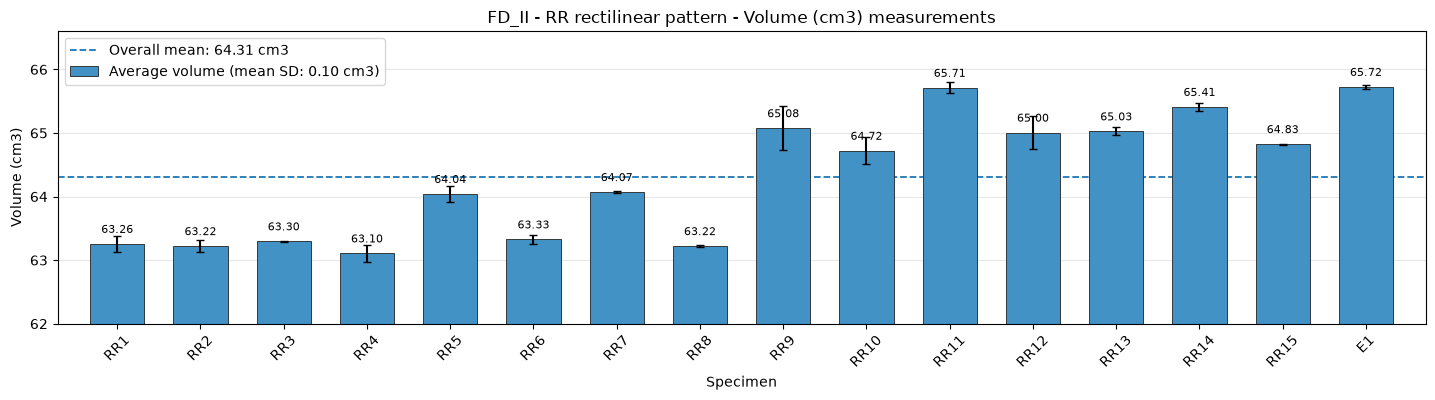

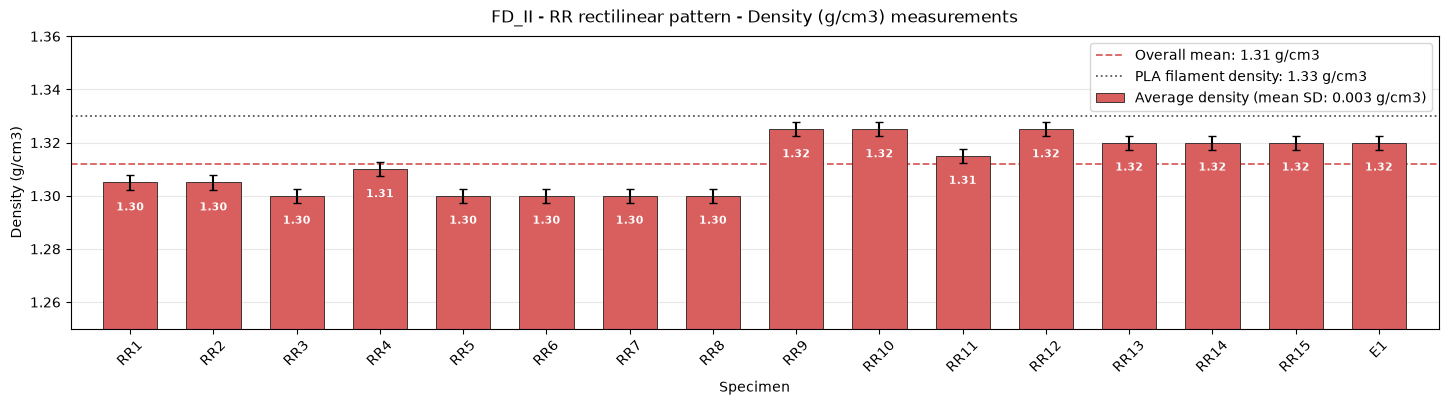

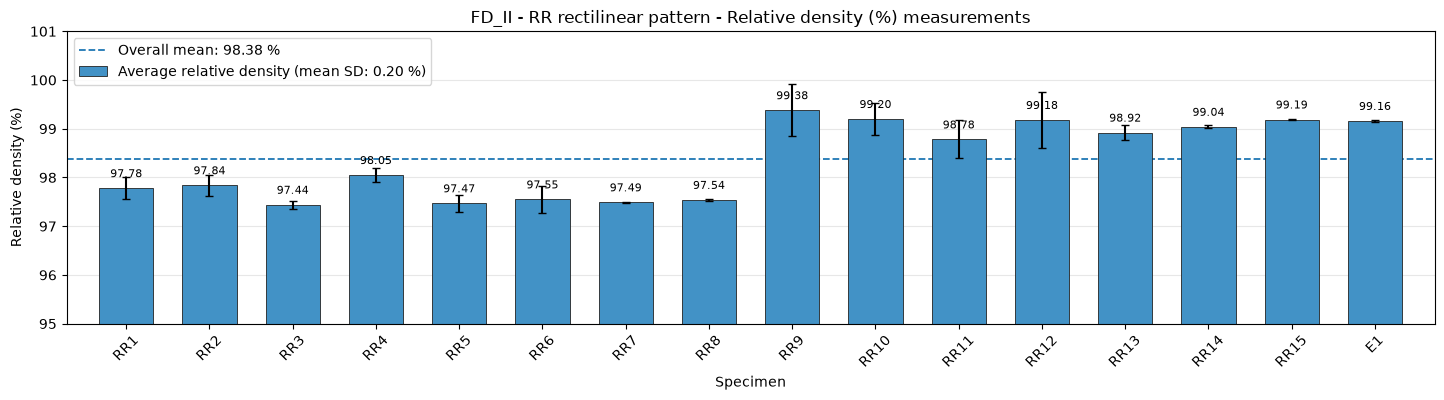

In [30]:
fd_II_volume_plot = fd_II_hydrostatic_tables["volume_cm3"].dropna(
    subset=["volume_cm3_mean"],
)
fd_II_density_plot = fd_II_hydrostatic_tables["density_g_cm3"].dropna(
    subset=["density_g_cm3_mean"],
).copy()
fd_II_relative_density_plot = fd_II_hydrostatic_tables["relative_density_percent"].dropna(
    subset=["relative_density_percent_mean"],
)
fd_II_density_repeatability = fd_II_relative_density_plot[[
    "run",
    "relative_density_percent_mean",
    "relative_density_percent_std",
]]
fd_II_density_plot = fd_II_density_plot.merge(
    fd_II_density_repeatability, on="run", how="left",
)
fd_II_density_plot["density_g_cm3_std"] = (
    fd_II_density_plot["density_g_cm3_mean"]
    * fd_II_density_plot["relative_density_percent_std"]
    / fd_II_density_plot["relative_density_percent_mean"]
)

plot_response_measurements(
    fd_II_volume_plot,
    fd_II_hydrostatic_columns["volume_cm3"],
    response_name="volume_cm3",
    y_label="Volume (cm3)",
    y_min=62.0,
    y_max=66.6,
    mean_label="Average volume",
    experiment="FD_II - RR rectilinear pattern",
    value_digits=2,
    average_bars_only=True,
    show_overall_mean=True,
    average_legend_loc="upper left",
)

plot_response_measurements(
    fd_II_density_plot,
    fd_II_hydrostatic_columns["density_g_cm3"],
    response_name="density_g_cm3",
    y_label="Density (g/cm3)",
    y_min=1.25,
    y_max=1.36,
    mean_label="Average density",
    experiment="FD_II - RR rectilinear pattern",
    value_digits=2,
    uncertainty_digits=3,
    average_bars_only=True,
    average_bar_color="#d95f5f",
    show_overall_mean=True,
    overall_mean_color="#d95f5f",
    reference_value=1.33,
    reference_label="PLA filament density: 1.33 g/cm3",
    average_labels_inside=True,
    use_mean_sd_errorbars=True,
    title_pad=10,
)

plot_response_measurements(
    fd_II_relative_density_plot,
    fd_II_hydrostatic_columns["relative_density_percent"],
    response_name="relative_density_percent",
    y_label="Relative density (%)",
    y_min=95,
    y_max=101,
    mean_label="Average relative density",
    experiment="FD_II - RR rectilinear pattern",
    value_digits=2,
    average_bars_only=True,
    show_overall_mean=True,
    average_legend_loc="upper left",
)


### Mass, Volume, and Density Correlations

These plots compare the precision-scale mean mass with the hydrostatic volume and density measurements. Only RR specimens with all three responses are included. Pearson `r` describes the strength and direction of each linear relationship.


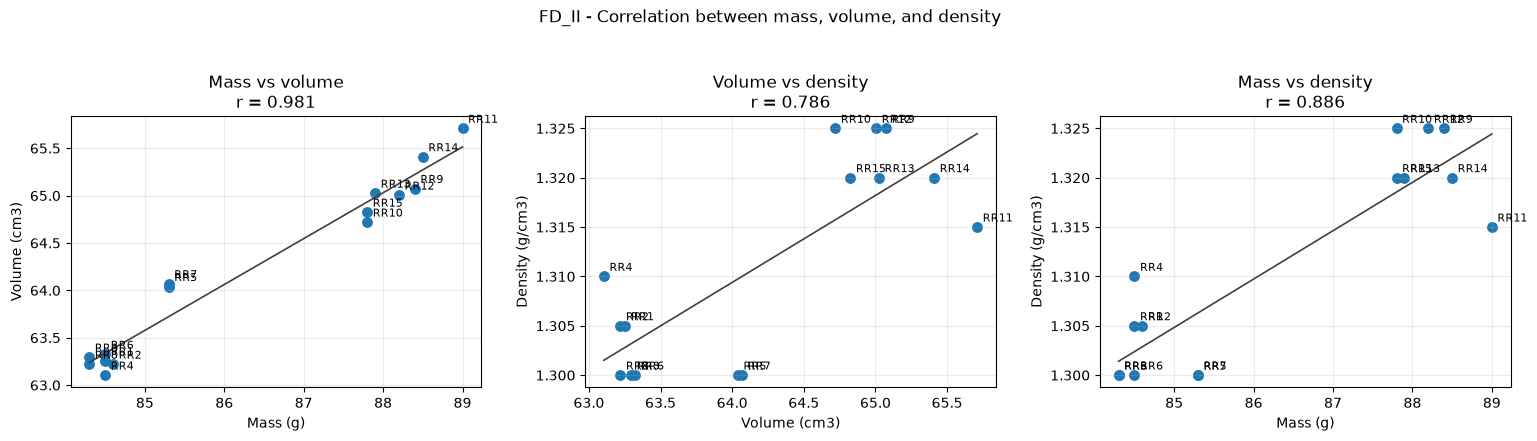

,run,mass_mean_g,volume_cm3_mean,density_g_cm3_mean
0,RR1,84.5,63.255,1.305
1,RR2,84.6,63.220,1.305
2,RR3,84.3,63.295,1.300
3,RR4,84.5,63.105,1.310
4,RR5,85.3,64.040,1.300
5,RR6,84.5,63.325,1.300
6,RR7,85.3,64.070,1.300
7,RR8,84.3,63.220,1.300
8,RR9,88.4,65.075,1.325
9,RR10,87.8,64.720,1.325


,comparison,n,pearson_r
0,Mass vs volume,15,0.981
1,Volume vs density,15,0.786
2,Mass vs density,15,0.886


In [31]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

fd_II_correlation_data = (
    mass_measurements_g[["run", "mass_mean_g"]]
    .merge(
        fd_II_hydrostatic_tables["volume_cm3"][["run", "volume_cm3_mean"]],
        on="run",
        how="inner",
    )
    .merge(
        fd_II_hydrostatic_tables["density_g_cm3"][["run", "density_g_cm3_mean"]],
        on="run",
        how="inner",
    )
    .dropna(subset=["mass_mean_g", "volume_cm3_mean", "density_g_cm3_mean"])
)

fd_II_correlation_pairs = [
    ("mass_mean_g", "volume_cm3_mean", "Mass (g)", "Volume (cm3)", "Mass vs volume"),
    ("volume_cm3_mean", "density_g_cm3_mean", "Volume (cm3)", "Density (g/cm3)", "Volume vs density"),
    ("mass_mean_g", "density_g_cm3_mean", "Mass (g)", "Density (g/cm3)", "Mass vs density"),
]

fd_II_correlation_summary = []
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, fd_II_correlation_pairs):
    plot_df = fd_II_correlation_data[["run", x_col, y_col]].dropna()
    r_value = plot_df[x_col].corr(plot_df[y_col])
    fd_II_correlation_summary.append({
        "comparison": title,
        "n": len(plot_df),
        "pearson_r": r_value,
    })

    ax.scatter(plot_df[x_col], plot_df[y_col], color="#1f77b4", s=46)
    for _, row in plot_df.iterrows():
        ax.annotate(
            row["run"],
            (row[x_col], row[y_col]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

    if len(plot_df) >= 2:
        slope, intercept = np.polyfit(plot_df[x_col], plot_df[y_col], 1)
        x_line = np.linspace(plot_df[x_col].min(), plot_df[x_col].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, color="0.25", linewidth=1.2)

    ax.set_title(f"{title}\nr = {r_value:.3f}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)

fig.suptitle("FD_II - Correlation between mass, volume, and density", y=1.04)
plt.tight_layout()
plt.show(block=False)

display(fd_II_correlation_data.round({
    "mass_mean_g": 3,
    "volume_cm3_mean": 3,
    "density_g_cm3_mean": 3,
}))
display(pd.DataFrame(fd_II_correlation_summary).round({"pearson_r": 3}))


### Regression Analysis - RR-E1 Density Model

The available RR density measurements and `E1` are ordered from lowest to highest mean density. An RR-only five-factor model cannot be estimated from `RR1`-`RR12` because those available rows are rank-deficient. The density analysis therefore uses a clearly labeled augmented model fitted to `RR1`-`RR12 + E1`; `RR13`-`RR16` remain missing. These are linear screening contours because FD_II has only two levels per factor.


,run,density_g_cm3_1,density_g_cm3_2,density_g_cm3_mean,density_g_cm3_std
0,RR3,1.30,1.30,1.300,0.001
1,RR5,1.30,1.30,1.300,0.002
2,RR6,1.30,1.30,1.300,0.004
3,RR7,1.30,1.30,1.300,0.000
4,RR8,1.30,1.30,1.300,0.000
5,RR1,1.30,1.31,1.305,0.003
6,RR2,1.30,1.31,1.305,0.003
7,RR4,1.31,1.31,1.310,0.002
8,RR11,1.31,1.32,1.315,0.005
9,E1,1.32,1.32,1.320,0.000


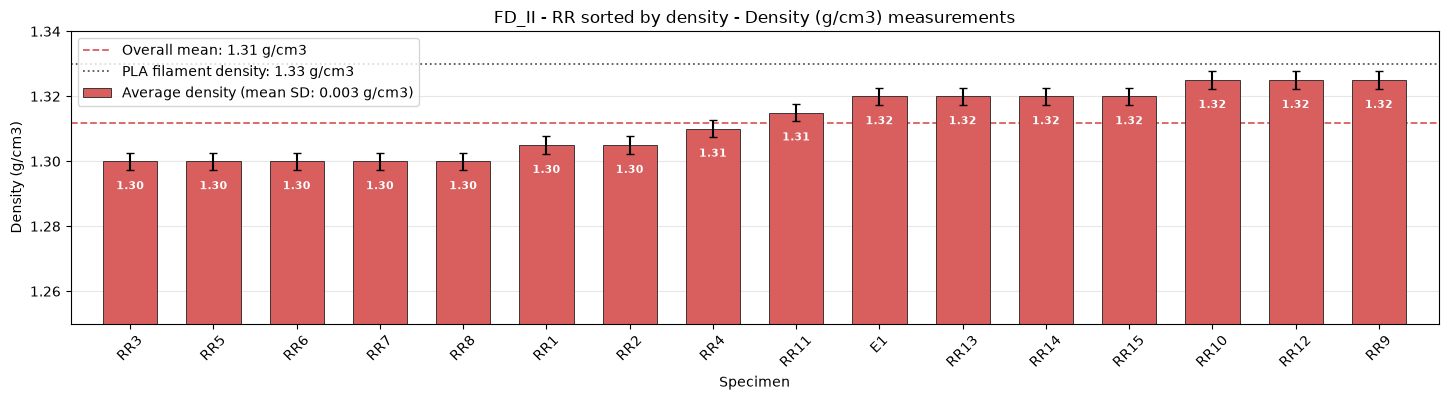

,available_runs,required_model_terms,rank,full_rank,residual_df,r_squared,residual_std
0,16,6,6,True,10,0.94,0.0031


,run,n_group,group_mean,SS_measurement_group,df_measurement_group
0,E1,2,1.32000,0.00000,1
1,RR1,2,1.30507,0.00001,1
2,RR10,2,1.32500,0.00002,1
3,RR11,2,1.31493,0.00003,1
4,RR12,2,1.32507,0.00006,1
5,RR13,2,1.32000,0.00000,1
6,RR14,2,1.32000,0.00000,1
7,RR15,2,1.32000,0.00000,1
8,RR2,2,1.30500,0.00001,1
9,RR3,2,1.30000,0.00000,1


,measurement_groups,measurement_observations,SS_measurement,df_measurement,MSE_measurement,s_measurement
0,16,32,0.0002,16,0.00001,0.00353


,source,df,sum_sq,mean_sq,F_value,p_value
0,Model,5,0.00150,0.00030,31.31354,0.00001
1,Residual,10,0.00010,0.00001,NaN,NaN
2,Total,15,0.00159,NaN,NaN,NaN


,error_basis,SS,df,MSE,s
0,regression residual,0.0001,10.0,0.00001,0.00309
1,measurement repeatability,0.0002,16.0,0.00001,0.00353


,term,coefficient,standard_error,t_value,F_value,p_value,pure_standard_error,pure_t_value,pure_F_value,pure_p_value,measurement_standard_error,measurement_t_value,measurement_F_value,measurement_p_value
1,A_flow_ratio,0.00952,0.00079,11.99151,143.79638,0.00000,NaN,NaN,NaN,NaN,0.00091,10.50533,110.36198,0.00000
2,B_nozzle_temp,-0.00173,0.00079,-2.17507,4.73094,0.05470,NaN,NaN,NaN,NaN,0.00091,-1.90550,3.63094,0.07485
3,C_speed,-0.00065,0.00079,-0.81565,0.66529,0.43370,NaN,NaN,NaN,NaN,0.00091,-0.71456,0.51060,0.48517
4,D_line_width,0.00123,0.00079,1.54545,2.38840,0.15327,NaN,NaN,NaN,NaN,0.00091,1.35391,1.83307,0.19458
5,E_layer_height,0.00060,0.00079,0.75841,0.57519,0.46570,NaN,NaN,NaN,NaN,0.00091,0.66442,0.44145,0.51588


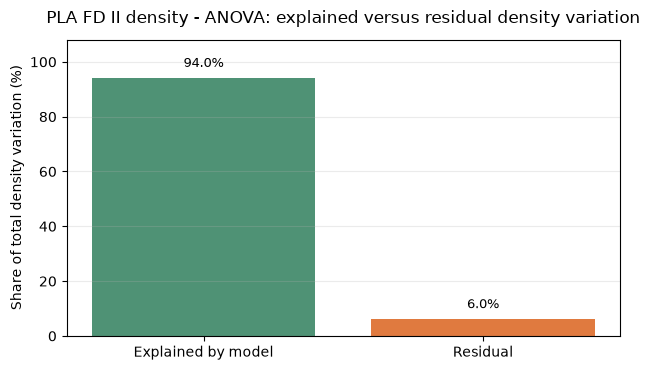

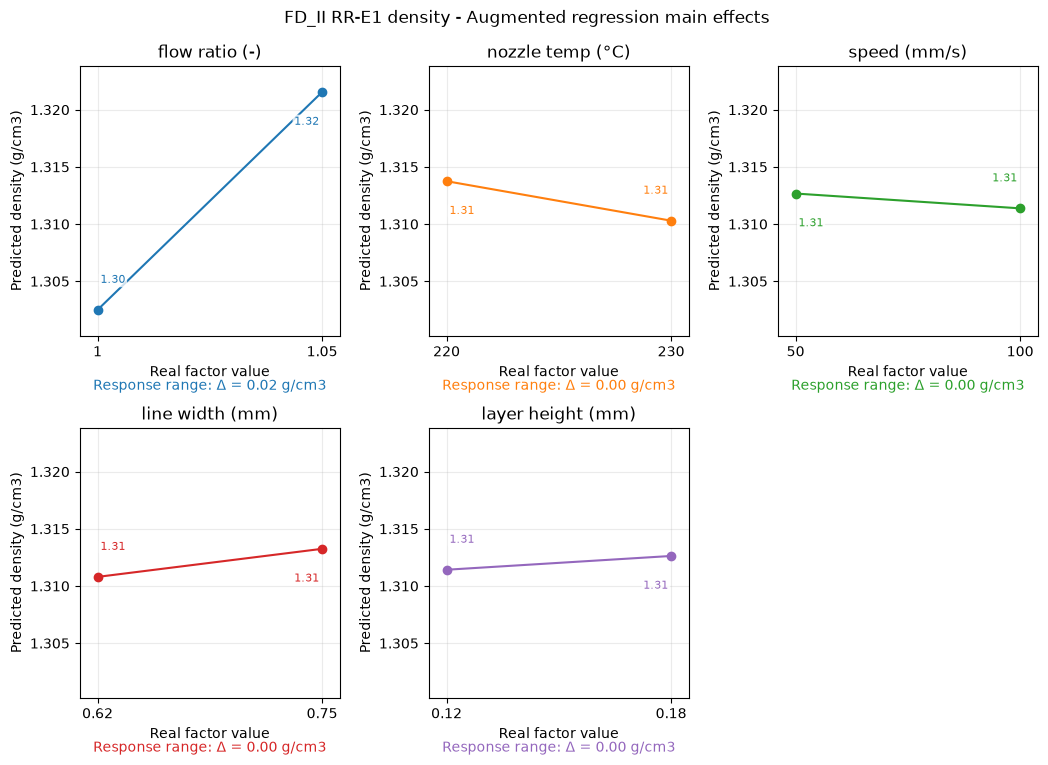

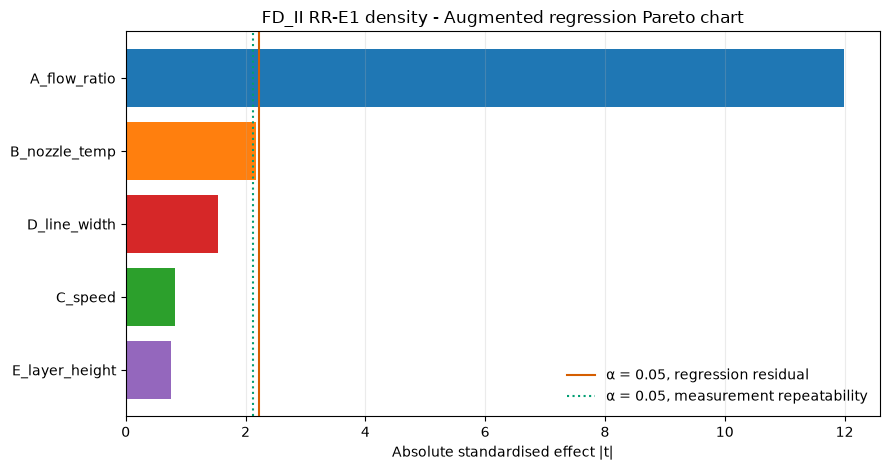

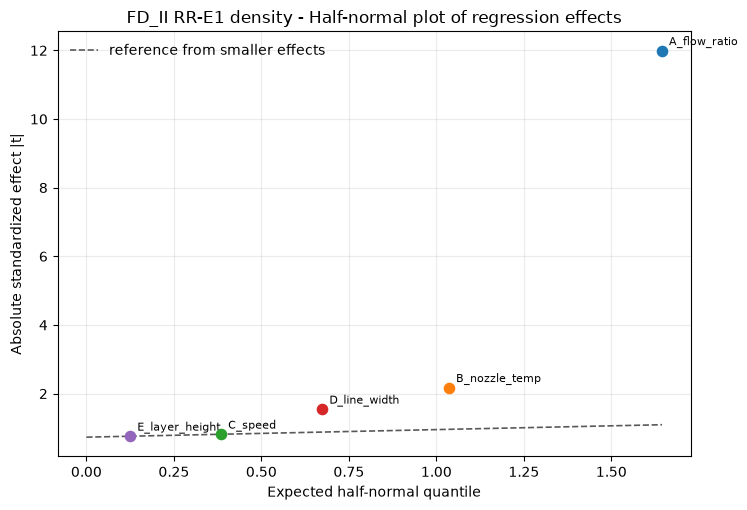

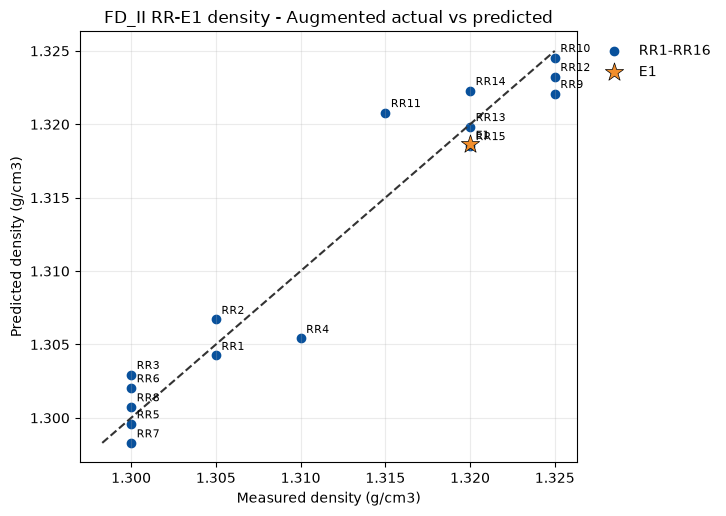

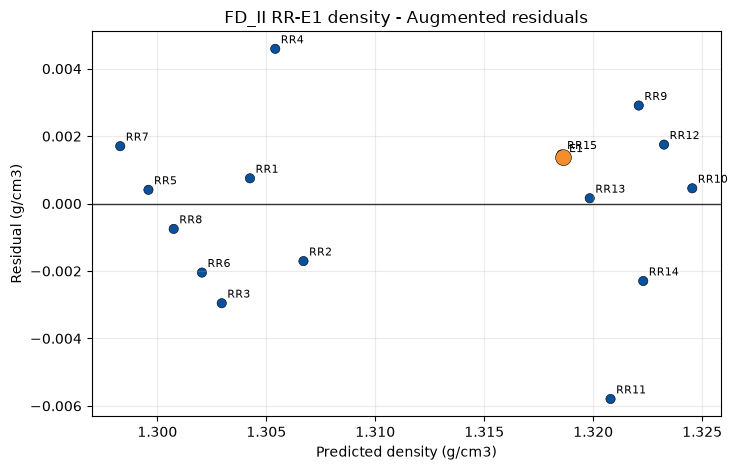

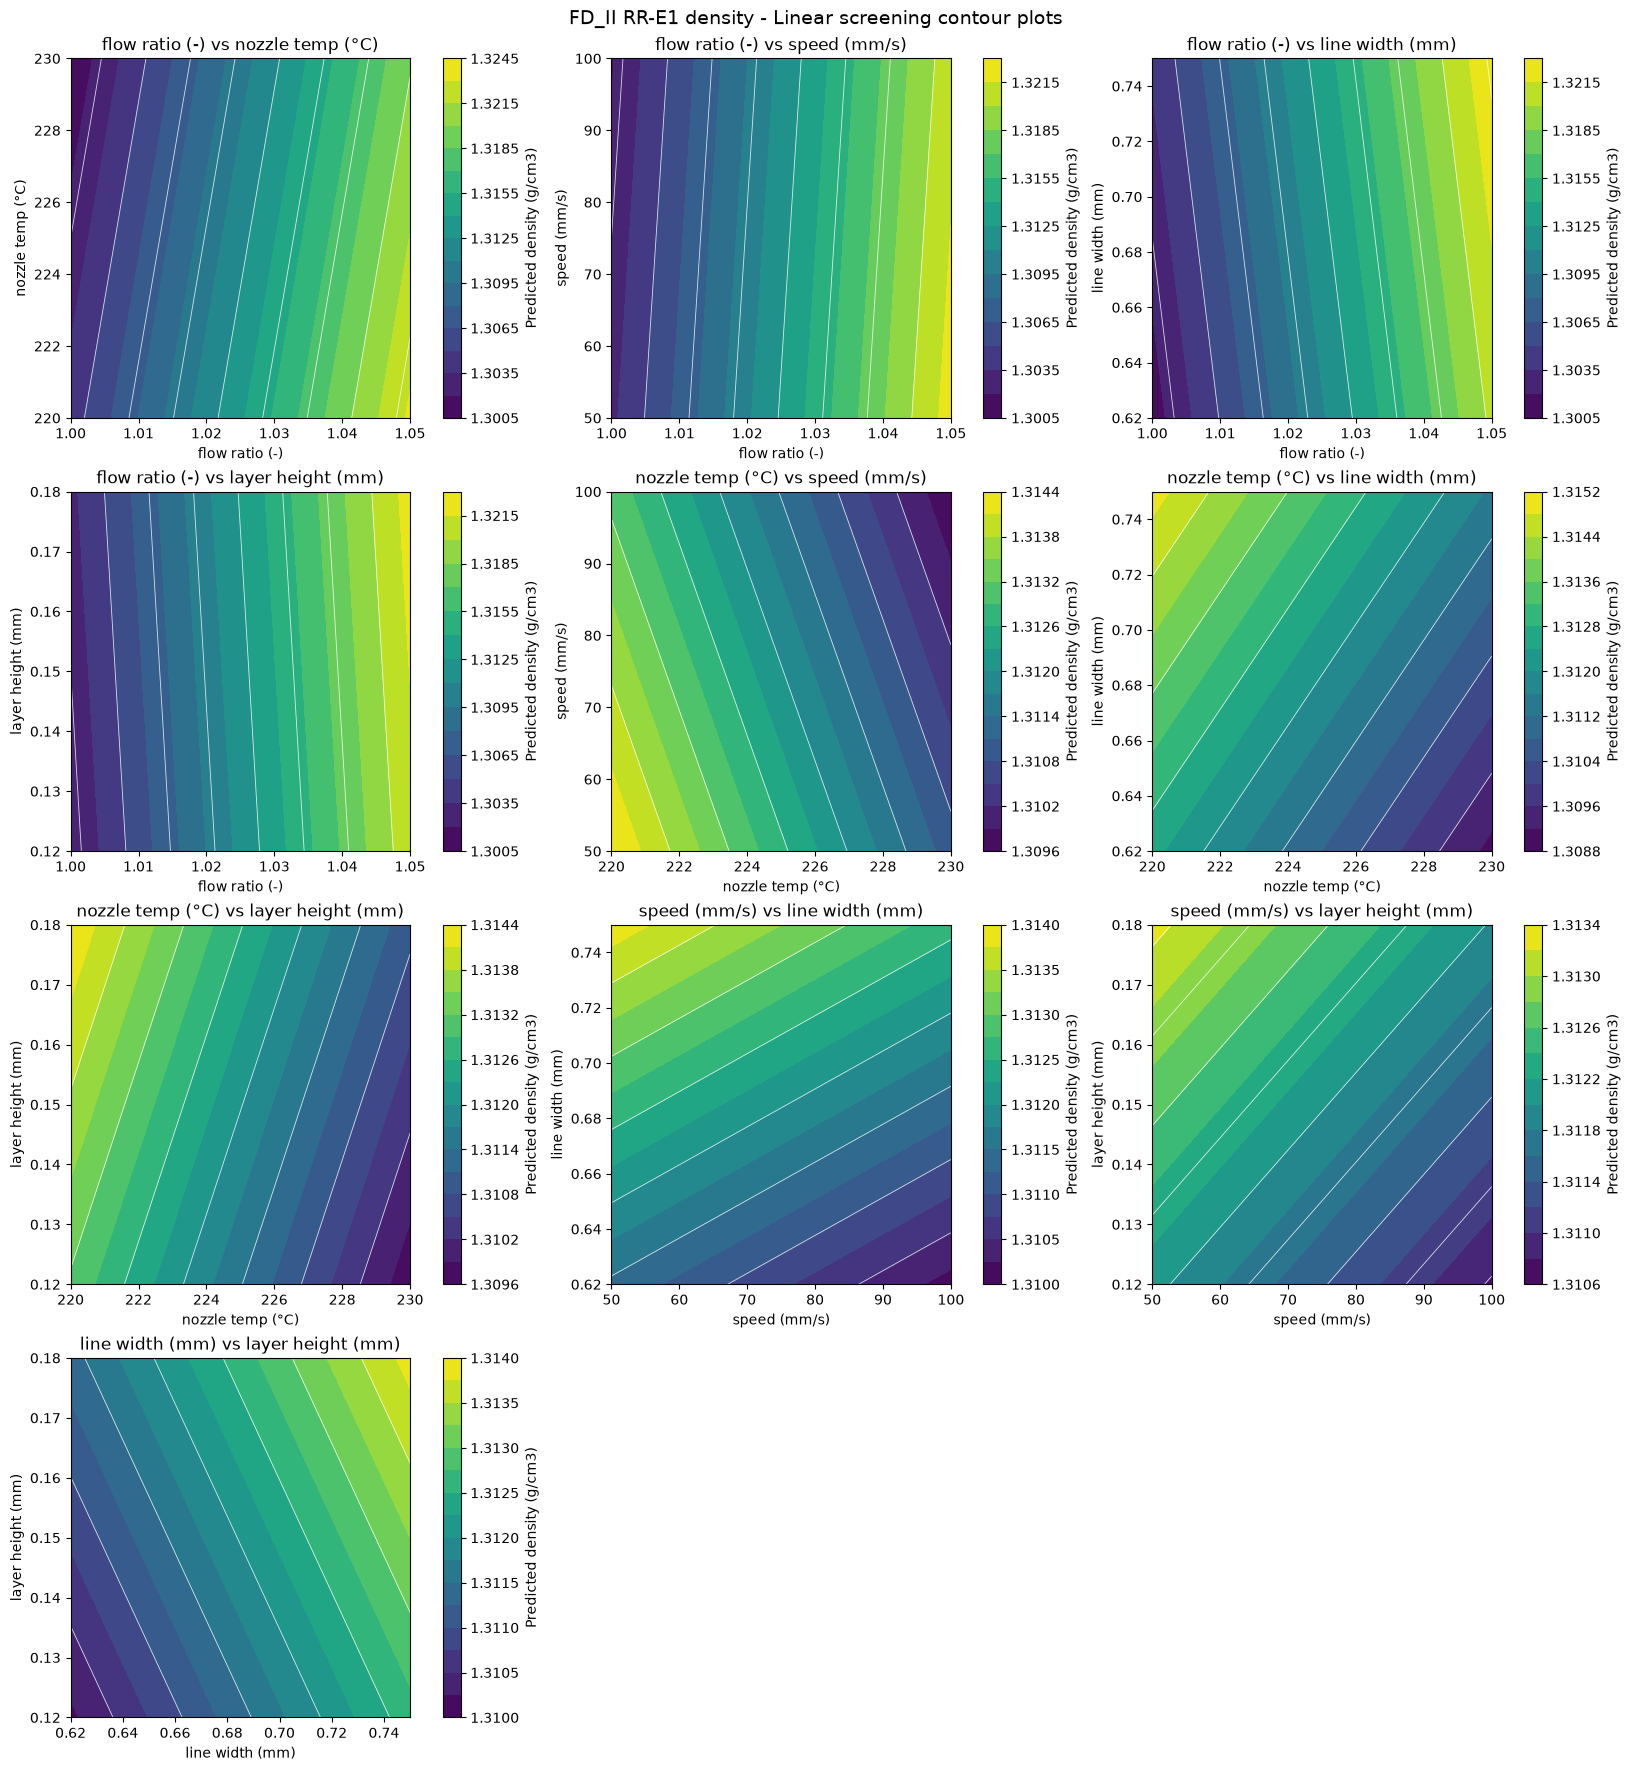

In [32]:
fd_II_density_sorted = (
    fd_II_hydrostatic_tables["density_g_cm3"]
    .dropna(subset=["density_g_cm3_mean"])
    .sort_values(["density_g_cm3_mean", "run"])
    .reset_index(drop=True)
)
fd_II_relative_density_stats = fd_II_hydrostatic_tables["relative_density_percent"][[
    "run",
    "relative_density_percent_mean",
    "relative_density_percent_std",
]]
fd_II_density_sorted = fd_II_density_sorted.merge(
    fd_II_relative_density_stats, on="run", how="left",
)
fd_II_density_sorted["density_g_cm3_std"] = (
    fd_II_density_sorted["density_g_cm3_mean"]
    * fd_II_density_sorted["relative_density_percent_std"]
    / fd_II_density_sorted["relative_density_percent_mean"]
)

display(fd_II_density_sorted[[
    "run",
    *fd_II_hydrostatic_columns["density_g_cm3"],
    "density_g_cm3_mean",
    "density_g_cm3_std",
]].round(3))

plot_response_measurements(
    fd_II_density_sorted,
    fd_II_hydrostatic_columns["density_g_cm3"],
    response_name="density_g_cm3",
    y_label="Density (g/cm3)",
    y_min=1.25,
    y_max=1.34,
    mean_label="Average density",
    experiment="FD_II - RR sorted by density",
    value_digits=2,
    uncertainty_digits=3,
    average_bars_only=True,
    average_bar_color="#d95f5f",
    show_overall_mean=True,
    overall_mean_color="#d95f5f",
    reference_value=1.33,
    reference_label="PLA filament density: 1.33 g/cm3",
    average_legend_loc="upper left",
    average_labels_inside=True,
    use_mean_sd_errorbars=True,
)

FD_II_DENSITY_FACTOR_COLUMNS = [
    "A_flow_ratio",
    "B_nozzle_temp",
    "C_speed",
    "D_line_width",
    "E_layer_height",
]
fd_II_density_rr_measurements = fd_II_hydrostatic_tables["density_g_cm3"].loc[
    lambda table: table["run"].str.fullmatch(r"RR(?:[1-9]|1[0-6])")
].copy()
fd_II_density_rr_result_matrix = build_result_matrix(
    fd_II_coded_df,
    fd_II_density_rr_measurements,
    response="density_g_cm3_mean",
)
fd_II_density_rr_result_matrix["Run"] = [f"RR{i}" for i in range(1, 17)]
fd_II_e1_density = fd_II_hydrostatic_tables["density_g_cm3"].loc[
    lambda table: table["run"].eq("E1"),
    "density_g_cm3_mean",
].iloc[0]
fd_II_e1_definition = next(run for run in FD_II_RUNS if run["run"] == "E1")
fd_II_density_e1_row = pd.DataFrame([{
    "Run": "E1",
    **fd_II_e1_definition["coded_parameters"],
    "density_g_cm3_mean": fd_II_e1_density,
}])
fd_II_density_augmented_result_matrix = pd.concat(
    [fd_II_density_rr_result_matrix, fd_II_density_e1_row],
    ignore_index=True,
)
fd_II_density_model = fit_main_effect_screening_model(
    fd_II_density_augmented_result_matrix,
    response="density_g_cm3_mean",
    factor_cols=FD_II_DENSITY_FACTOR_COLUMNS,
)
assert bool(fd_II_density_model["info_df"].loc[0, "full_rank"])
display(fd_II_density_model["info_df"].round(4))
fd_II_density_repeatability = fd_II_hydrostatic_tables["relative_density_percent"].merge(
    fd_II_hydrostatic_tables["density_g_cm3"][["run", "density_g_cm3_mean"]],
    on="run", how="left",
)
fd_II_density_repeatability_columns = []
for repeat_index, relative_column in enumerate(
    fd_II_hydrostatic_columns["relative_density_percent"], start=1,
):
    density_column = f"density_g_cm3_repeat_{repeat_index}"
    fd_II_density_repeatability[density_column] = (
        fd_II_density_repeatability[relative_column]
        * fd_II_density_repeatability["density_g_cm3_mean"]
        / fd_II_density_repeatability["relative_density_percent_mean"]
    )
    fd_II_density_repeatability_columns.append(density_column)
fd_II_density_measurement_observations, fd_II_density_measurement_groups, fd_II_density_measurement_summary = (
    calculate_measurement_error_from_repeated_columns(
        fd_II_density_repeatability,
        fd_II_density_repeatability_columns,
        "density_g_cm3_mean",
    )
)
display(fd_II_density_measurement_groups.round(5))
display(fd_II_density_measurement_summary.round(5))
fd_II_density_anova = build_model_anova_table(fd_II_density_model)
display(fd_II_density_anova.round(5))
display(build_error_comparison_table(
    fd_II_density_model,
    measurement_error_summary=fd_II_density_measurement_summary,
).round(5))
display(build_term_significance_table(
    fd_II_density_model,
    measurement_error_summary=fd_II_density_measurement_summary,
).round(5))
plot_model_anova(
    fd_II_density_anova,
    response="density_g_cm3_mean",
    experiment="PLA FD II density",
    variation_percent=True,
)
plot_augmented_main_effects(
    fd_II_density_model,
    FD_II_LEVELS,
    experiment="FD_II RR-E1 density",
)
plot_augmented_model_pareto(
    fd_II_density_model,
    experiment="FD_II RR-E1 density",
    measurement_error_summary=fd_II_density_measurement_summary,
)
plot_screening_half_normal(
    fd_II_density_model,
    experiment="FD_II RR-E1 density",
)
plot_augmented_observed_vs_predicted(
    fd_II_density_model,
    confirmation_run="E1",
    experiment="FD_II RR-E1 density",
)
plot_augmented_residuals(
    fd_II_density_model,
    confirmation_run="E1",
    experiment="FD_II RR-E1 density",
)
plot_screening_response_contours(
    fd_II_density_model,
    levels=FD_II_LEVELS,
    max_columns=3,
    experiment="FD_II RR-E1 density",
)


## 5) Fitted Score Response Analysis

This comparison keeps mass, density, the fitted score, and only the two vacuum parameters used by the fitted score: $P_{34h}$ and $\alpha_{24-48h}$. Pressure rise and unrelated vacuum metrics are excluded.

Using PLA vacuum score tables:
  - C:\Users\sarklug\Documents\Visual Studio Code\Vacuum_pump-Project\vacuum_pump_chamber_outputs\R_series\overview\tables\r_series_overview_metric_scores.csv
  - C:\Users\sarklug\Documents\Visual Studio Code\Vacuum_pump-Project\vacuum_pump_chamber_outputs\R_series\pump_down\tables\r_series_overview_metric_scores.csv
Skipped unavailable vacuum metrics:
  - Pressure $P_{34h}$ [mbar]: missing column P_34h_mbar_value


,experiment,run,A_flow_ratio,B_nozzle_temp,C_speed,D_line_width,E_layer_height,weight_g,density_g_cm3,density_fitted_score_0_worst_1_best,desorption_alpha_24_48_value
0,PLA R01,RR1,-1,-1,-1,-1,1,84.5,1.305,0.307091,1.827179
1,PLA R02,RR2,-1,-1,-1,1,1,84.6,1.305,0.362759,1.601505
2,PLA R03,RR3,-1,-1,1,-1,1,84.3,1.300,0.248762,1.520343
3,PLA R04,RR4,-1,-1,1,1,1,84.5,1.310,0.507843,1.237978
4,PLA R05,RR5,-1,1,-1,-1,-1,85.3,1.300,0.000000,1.960249
5,PLA R06,RR6,-1,1,-1,1,-1,84.5,1.300,0.354959,1.870983
6,PLA R07,RR7,-1,1,1,-1,-1,85.3,1.300,0.261536,1.783295
7,PLA R08,RR8,-1,1,1,1,-1,84.3,1.300,0.507704,1.517743
8,PLA R09,RR9,1,-1,-1,-1,-1,88.4,1.325,0.869541,0.538290
9,PLA R10,RR10,1,-1,-1,1,-1,87.8,1.325,1.000000,0.567246


,metric,factor,low_mean,high_mean,effect_high_minus_low,effect_percent_of_low_mean,n_low,n_high,p_value,residual_df
0,Mass [g],A_flow_ratio,84.662500,88.228571,3.566071,4.212103,8,7,7.268096e-08,9
1,Mass [g],B_nozzle_temp,86.412500,86.228571,-0.183929,-0.212849,8,7,9.305329e-01,9
2,Mass [g],C_speed,86.437500,86.200000,-0.237500,-0.274765,8,7,8.959924e-01,9
3,Mass [g],D_line_width,86.562500,86.057143,-0.505357,-0.583806,8,7,2.410779e-01,9
4,Mass [g],E_layer_height,86.600000,86.014286,-0.585714,-0.676344,8,7,1.460299e-01,9
5,Density [g/cm3],A_flow_ratio,1.302500,1.321429,0.018929,1.453249,8,7,1.393805e-06,9
6,Density [g/cm3],B_nozzle_temp,1.313750,1.308571,-0.005179,-0.394182,8,7,6.013763e-02,9
7,Density [g/cm3],C_speed,1.312500,1.310000,-0.002500,-0.190476,8,7,5.215519e-01,9
8,Density [g/cm3],D_line_width,1.310625,1.312143,0.001518,0.115812,8,7,1.540970e-01,9
9,Density [g/cm3],E_layer_height,1.311250,1.311429,0.000179,0.013618,8,7,4.360393e-01,9


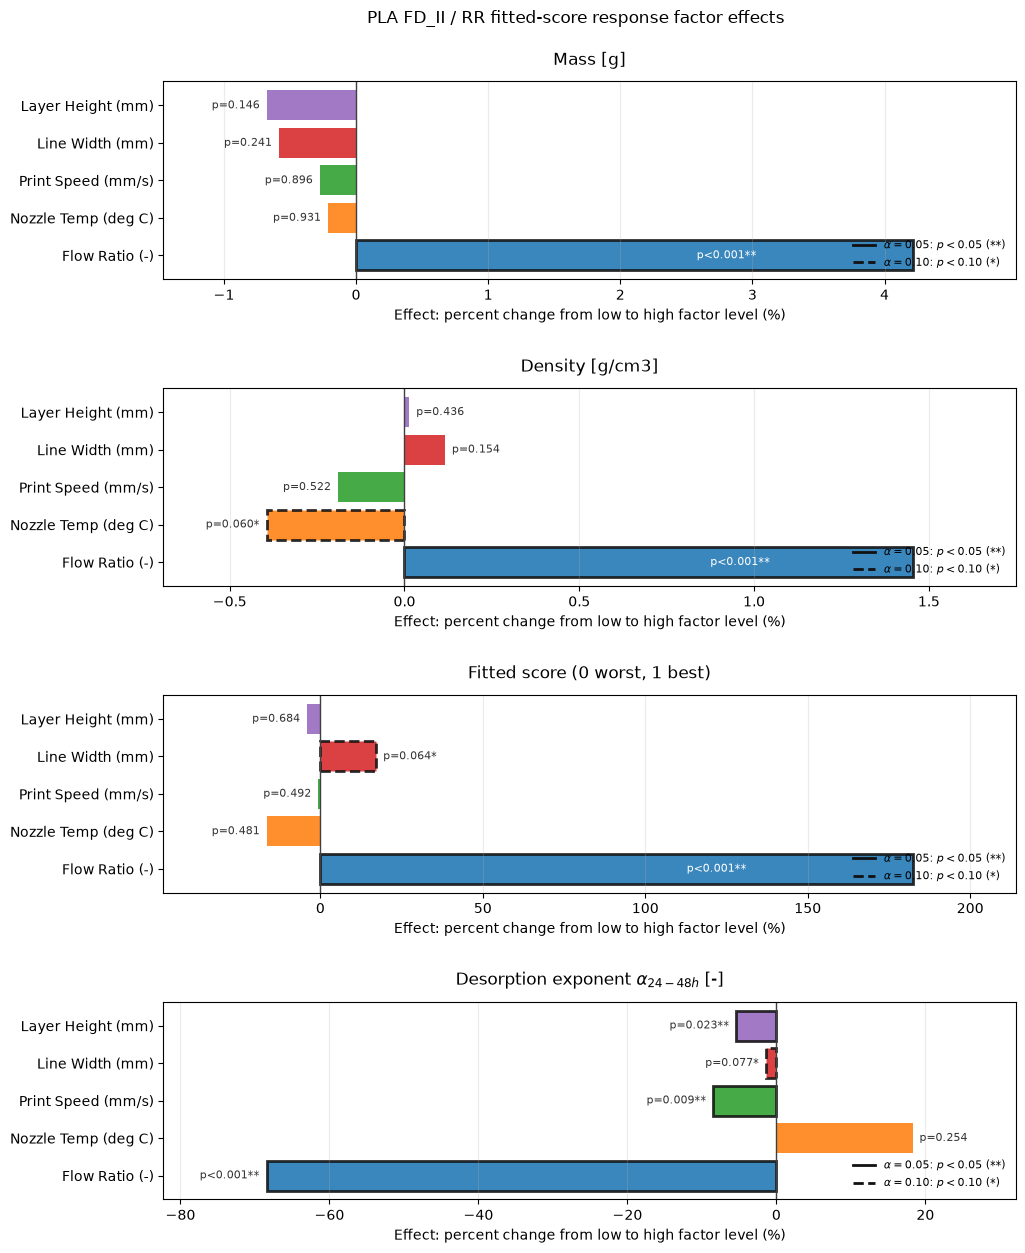

In [33]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pla_doe_measurements import (
    FD_II_HYDROSTATIC_MEASUREMENTS,
    FD_II_MASS_MEASUREMENTS_G,
    FD_II_RUNS,
)

PLA_VACUUM_OVERVIEW_SCORE_PATHS = [
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/overview/tables/r_series_overview_metric_scores.csv"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/overview/tables/r_series_overview_metric_scores.csv"),
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/pump_down/tables/r_series_overview_metric_scores.csv"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/pump_down/tables/r_series_overview_metric_scores.csv"),
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/tables/r_series_overview_metric_scores.csv"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series/tables/r_series_overview_metric_scores.csv"),
]
PLA_VACUUM_OVERVIEW_SEARCH_ROOTS = [
    Path("../Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series"),
    Path("Vacuum_pump-Project/vacuum_pump_chamber_outputs/R_series"),
]

pla_vacuum_score_paths = []
seen_score_paths = set()
score_path_candidates = [
    *PLA_VACUUM_OVERVIEW_SCORE_PATHS,
    *(
        candidate
        for root in PLA_VACUUM_OVERVIEW_SEARCH_ROOTS
        if root.exists()
        for candidate in root.rglob("r_series_overview_metric_scores.csv")
    ),
]
for score_path in score_path_candidates:
    if not score_path.exists():
        continue
    resolved_path = score_path.resolve()
    if resolved_path in seen_score_paths:
        continue
    seen_score_paths.add(resolved_path)
    pla_vacuum_score_paths.append(resolved_path)

if not pla_vacuum_score_paths:
    searched_paths = [str(path) for path in PLA_VACUUM_OVERVIEW_SCORE_PATHS]
    searched_roots = [str(path) for path in PLA_VACUUM_OVERVIEW_SEARCH_ROOTS]
    raise FileNotFoundError(
        "Could not find r_series_overview_metric_scores.csv. "
        f"Checked paths: {searched_paths}; searched roots: {searched_roots}"
    )

print("Using PLA vacuum score tables:")
for score_path in pla_vacuum_score_paths:
    print(f"  - {score_path}")

pla_vacuum_score_frames = [pd.read_csv(path) for path in pla_vacuum_score_paths]
pla_vacuum_scores = pla_vacuum_score_frames[0].set_index("experiment")
for score_frame in pla_vacuum_score_frames[1:]:
    pla_vacuum_scores = pla_vacuum_scores.combine_first(
        score_frame.set_index("experiment")
    )
pla_vacuum_scores = pla_vacuum_scores.reset_index()

FD_II_WEIGHT_RESPONSE = "weight_g"
fd_ii_weight_measurements_g, _ = build_mass_measurements(
    FD_II_MASS_MEASUREMENTS_G,
    run_labels=[run["run"] for run in FD_II_RUNS],
)
fd_ii_weight_measurements_g = fd_ii_weight_measurements_g.rename(
    columns={"mass_mean_g": FD_II_WEIGHT_RESPONSE}
)[["run", FD_II_WEIGHT_RESPONSE]]

FD_II_DENSITY_RESPONSE = "density_g_cm3"
fd_ii_density_measurements_g_cm3, _ = build_response_measurements(
    FD_II_HYDROSTATIC_MEASUREMENTS[FD_II_DENSITY_RESPONSE],
    run_labels=[run["run"] for run in FD_II_RUNS],
    response_name=FD_II_DENSITY_RESPONSE,
    mean_round_digits=3,
)
fd_ii_density_measurements_g_cm3 = fd_ii_density_measurements_g_cm3.rename(
    columns={f"{FD_II_DENSITY_RESPONSE}_mean": FD_II_DENSITY_RESPONSE}
)[["run", FD_II_DENSITY_RESPONSE]]

PLA_VACUUM_METRICS = {
    "Mass [g]": FD_II_WEIGHT_RESPONSE,
    "Density [g/cm3]": FD_II_DENSITY_RESPONSE,
    "Fitted score (0 worst, 1 best)": "density_fitted_score_0_worst_1_best",
    "Pressure $P_{34h}$ [mbar]": "P_34h_mbar_value",
    r"Desorption exponent $\alpha_{24-48h}$ [-]": "desorption_alpha_24_48_value",
}

def pla_run_label(experiment):
    match = re.fullmatch(r"PLA R0?(\d+)", str(experiment).strip())
    if not match:
        return None
    return f"RR{int(match.group(1))}"

fd_ii_design_rows = []
for run in FD_II_RUNS:
    row = {"run": run["run"]}
    row.update(run["coded_parameters"])
    row.update({f"{factor}_real": value for factor, value in run["parameters"].items()})
    fd_ii_design_rows.append(row)

fd_ii_design_for_vacuum = pd.DataFrame(fd_ii_design_rows)
pla_vacuum_scores = pla_vacuum_scores.assign(run=pla_vacuum_scores["experiment"].map(pla_run_label))
pla_vacuum_effect_data = pla_vacuum_scores.dropna(subset=["run"]).merge(
    fd_ii_design_for_vacuum,
    on="run",
    how="left",
).merge(
    fd_ii_weight_measurements_g,
    on="run",
    how="left",
).merge(
    fd_ii_density_measurements_g_cm3,
    on="run",
    how="left",
)

AVAILABLE_PLA_VACUUM_METRICS = {
    label: column
    for label, column in PLA_VACUUM_METRICS.items()
    if column in pla_vacuum_effect_data.columns
}
missing_vacuum_metrics = {
    label: column
    for label, column in PLA_VACUUM_METRICS.items()
    if column not in pla_vacuum_effect_data.columns
}
if missing_vacuum_metrics:
    print("Skipped unavailable vacuum metrics:")
    for label, column in missing_vacuum_metrics.items():
        print(f"  - {label}: missing column {column}")

factor_cols = list(FD_II_LEVELS)
effect_rows = []
for metric_label, metric_col in AVAILABLE_PLA_VACUUM_METRICS.items():
    metric_model = fit_main_effect_screening_model(
        pla_vacuum_effect_data[[*factor_cols, metric_col]],
        response=metric_col,
        factor_cols=factor_cols,
    )
    metric_statistics = metric_model["statistics_df"].set_index("term")
    residual_df = int(metric_model["info_df"].loc[0, "residual_df"])
    for factor in factor_cols:
        low_values = pla_vacuum_effect_data.loc[
            pla_vacuum_effect_data[factor] == -1, metric_col
        ].dropna()
        high_values = pla_vacuum_effect_data.loc[
            pla_vacuum_effect_data[factor] == 1, metric_col
        ].dropna()
        low_mean = low_values.mean() if len(low_values) else np.nan
        high_mean = high_values.mean() if len(high_values) else np.nan
        effect = np.nan
        effect_percent = np.nan
        if len(low_values) and len(high_values):
            effect = high_mean - low_mean
            if low_mean != 0 and np.isfinite(low_mean):
                effect_percent = 100 * effect / abs(low_mean)
        regression_p_value = metric_statistics.loc[factor, "p_value"]
        effect_rows.append({
            "metric": metric_label,
            "factor": factor,
            "low_mean": low_mean,
            "high_mean": high_mean,
            "effect_high_minus_low": effect,
            "effect_percent_of_low_mean": effect_percent,
            "n_low": len(low_values),
            "n_high": len(high_values),
            "p_value": regression_p_value,
            "residual_df": residual_df,
        })

pla_vacuum_effects = pd.DataFrame(effect_rows)

display(pla_vacuum_effect_data[[
    "experiment",
    "run",
    *factor_cols,
    *AVAILABLE_PLA_VACUUM_METRICS.values(),
]])
display(pla_vacuum_effects)

fig, axes = plt.subplots(
    len(AVAILABLE_PLA_VACUUM_METRICS),
    1,
    figsize=(11, 3.25 * len(AVAILABLE_PLA_VACUUM_METRICS)),
    constrained_layout=False,
)
if len(AVAILABLE_PLA_VACUUM_METRICS) == 1:
    axes = [axes]

factor_labels = [DISPLAY_NAMES.get(factor, factor) for factor in factor_cols]
for ax, metric_label in zip(axes, AVAILABLE_PLA_VACUUM_METRICS):
    plot_df = pla_vacuum_effects[pla_vacuum_effects["metric"] == metric_label].copy()
    plot_values = plot_df["effect_percent_of_low_mean"]
    colors = [FACTOR_COLORS.get(factor, "#7f7f7f") for factor in factor_cols]
    bars = ax.barh(factor_labels, plot_values, color=colors, alpha=0.88)
    ax.axvline(0, color="0.25", linewidth=1)
    ax.set_title(metric_label, pad=12)
    ax.set_xlabel("Effect: percent change from low to high factor level (%)")
    ax.grid(axis="x", alpha=0.25)
    for bar_index, (bar, effect, p_value) in enumerate(
        zip(bars, plot_values, plot_df["p_value"])
    ):
        if pd.isna(effect):
            ax.text(
                0,
                bar.get_y() + bar.get_height() / 2,
                "not estimable",
                va="center",
                ha="left",
                fontsize=8,
                color="0.35",
            )
            continue
        if pd.notna(p_value):
            if p_value < 0.05:
                bar.set_edgecolor("#111111")
                bar.set_linewidth(2.0)
                significance_mark = "**"
            elif p_value < 0.10:
                bar.set_edgecolor("#111111")
                bar.set_linewidth(2.0)
                bar.set_linestyle("--")
                significance_mark = "*"
            else:
                significance_mark = ""
            p_text = "p<0.001" if p_value < 0.001 else f"p={p_value:.3f}"
            place_inside = bar_index == 0 and effect > 0
            annotation_x = 0.72 * effect if place_inside else effect
            annotation_offset = 0 if place_inside else (5 if effect >= 0 else -5)
            ax.annotate(
                f"{p_text}{significance_mark}",
                xy=(annotation_x, bar.get_y() + bar.get_height() / 2),
                xytext=(annotation_offset, 0),
                textcoords="offset points",
                va="center",
                ha="right" if place_inside or effect < 0 else "left",
                fontsize=8,
                color="white" if place_inside else "0.2",
                clip_on=False,
            )
        else:
            ax.annotate(
                "p=n/e",
                xy=(effect, bar.get_y() + bar.get_height() / 2),
                xytext=(5 if effect >= 0 else -5, 0),
                textcoords="offset points",
                va="center",
                ha="left" if effect >= 0 else "right",
                fontsize=8,
                color="0.35",
                clip_on=False,
            )
    ax.margins(x=0.16)
    alpha_legend = [
        Line2D([0], [0], color="#111111", linewidth=2,
               label=r"$\alpha=0.05$: $p<0.05$ (**)"),
        Line2D([0], [0], color="#111111", linewidth=2, linestyle="--",
               label=r"$\alpha=0.10$: $p<0.10$ (*)"),
    ]
    if plot_df["p_value"].isna().all():
        alpha_legend.append(Line2D(
            [0], [0], color="none", label="p=n/e: model rank deficient"
        ))
    ax.legend(
        handles=alpha_legend, loc="lower right", frameon=False, fontsize=8
    )

fig.suptitle("PLA FD_II / RR fitted-score response factor effects", y=0.985)
fig.subplots_adjust(top=0.93, bottom=0.07, hspace=0.55)
plt.show()
